# Integrante:
- Branco Álvarez
- Benjamín Ibarra

In [1]:
import sys
!{sys.executable} -m pip install numpy pandas matplotlib scipy

  Using cached pandas-3.1.1-cp314-cp314-win_amd64.whl.metadata (16 kB)
Using cached pandas-3.1.1-cp314-cp314-win_amd64.whl (10.9 MB)



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from typing import Dict, Tuple, List, Optional, Iterable

Edge = Tuple[float, ...]


class BranchingProcessLattice:

    def __init__(self, dimension: int = 2, box: int = 3, kill_boundary: bool = False,
                 initial_config: Optional[Dict[Edge, int]] = None,
                 seed: Optional[int] = None, max_charge: Optional[int] = 1,
                 boundary: Optional[str] = None):
        if dimension not in (2, 3):
            raise ValueError("La dimensión debe ser 2 o 3.")
        if box < 1:
            raise ValueError("box debe ser >= 1.")
        self.d = dimension
        self.L = box
        if boundary is None:
            boundary = "absorb" if kill_boundary else "reflect"
        if boundary not in ("reflect", "absorb", "infinite"):
            raise ValueError('boundary debe ser "reflect", "absorb" o "infinite".')
        self.boundary = boundary
        self.kill_boundary = boundary == "absorb"
        self.infinite = boundary == "infinite"
        self.max_charge = max_charge
        self.rng = np.random.default_rng(seed)

        self.theta: Dict[Edge, int] = {}
        self._l1 = 0
        self._face_cache: Dict[Edge, List[Tuple[Edge, Dict[Edge, int]]]] = {}

        self.trajectory: List[Dict[Edge, int]] = []
        self._box_hist: List[int] = []
        self._snapshot_steps: Tuple[int, ...] = ()
        self._stats_cache = None

        if initial_config:
            for edge, charge in initial_config.items():
                self.add_particle(edge, charge)

    @staticmethod
    def _half_indices(p: Edge) -> List[int]:
        return [i for i, v in enumerate(p) if abs(v - round(v)) > 1e-5]

    def _in_box(self, p: Edge) -> bool:
        return all(abs(c) <= self.L + 1e-9 for c in p)

    def _is_boundary_edge(self, e: Edge) -> bool:
        k = self._half_indices(e)[0]
        return any(abs(abs(e[m]) - self.L) < 1e-9 for m in range(self.d) if m != k)

    def _grow(self):
        self.L += 1
        self._face_cache.clear()
        self._stats_cache = None

    def add_particle(self, edge: Edge, charge: int = 1):
        if len(edge) != self.d:
            raise ValueError(f"La arista {edge} debe tener dimensión {self.d}.")
        e = tuple(float(c) for c in edge)
        if len(self._half_indices(e)) != 1:
            raise ValueError(f"La arista {e} debe tener exactamente 1 coordenada semi-entera.")
        if not self._in_box(e):
            if not self.infinite:
                raise ValueError(f"La arista {e} está fuera de la caja [-{self.L}, {self.L}].")
            while not self._in_box(e):
                self._grow()
        self._update_edge(e, self.theta.get(e, 0) + charge)
        while self.infinite and any(self._is_boundary_edge(x) for x in self.theta):
            self._grow()
        self._stats_cache = None
        if self.trajectory:
            self.clear_trajectory()

    def add_loop(self, face_center: Edge, charge: int = 1, size=1):
        a, b = (size, size) if isinstance(size, int) else size
        if a < 1 or b < 1:
            raise ValueError("size debe ser >= 1.")
        f0 = tuple(float(x) for x in face_center)
        half = self._half_indices(f0)
        if len(half) != 2:
            raise ValueError(f"El centro de la cara {f0} debe tener exactamente 2 coordenadas semi-enteras.")
        i, j = sorted(half)

        total: Dict[Edge, int] = {}
        for p in range(a):
            for q in range(b):
                f = list(f0); f[i] += p; f[j] += q
                for e, c in self.get_boundary_of_face(tuple(f)).items():
                    total[e] = total.get(e, 0) + c
        total = {e: c for e, c in total.items() if c != 0}

        if not all(self._in_box(e) for e in total):
            raise ValueError("El lazo no cabe en la caja.")
        for e, c in total.items():
            self.add_particle(e, charge * c)

    def _update_edge(self, e: Edge, new: int):

        if self.max_charge is not None:
            new = max(-self.max_charge, min(self.max_charge, new))
        old = self.theta.get(e, 0)
        self._l1 += abs(new) - abs(old)
        if new == 0:
            self.theta.pop(e, None)
        else:
            self.theta[e] = new

    def get_boundary_of_face(self, f_center: Edge) -> Dict[Edge, int]:
        half = self._half_indices(f_center)
        if len(half) != 2:
            raise ValueError(f"El centro de la cara {f_center} debe tener exactamente 2 coordenadas semi-enteras.")
        i, j = sorted(half)
        b = {}
        e = list(f_center); e[i] += 0.5; b[tuple(e)] = +1
        e = list(f_center); e[i] -= 0.5; b[tuple(e)] = -1
        e = list(f_center); e[j] += 0.5; b[tuple(e)] = -1
        e = list(f_center); e[j] -= 0.5; b[tuple(e)] = +1
        return b

    def get_adjacent_faces(self, e_center: Edge) -> List[Tuple[Edge, Dict[Edge, int]]]:
        if e_center in self._face_cache:
            return self._face_cache[e_center]
        half = self._half_indices(e_center)
        if len(half) != 1:
            raise ValueError(f"El centro de la arista {e_center} debe tener exactamente 1 coordenada semi-entera.")
        k = half[0]
        faces = []
        for m in range(self.d):
            if m == k:
                continue
            for s in (+0.5, -0.5):
                f = list(e_center); f[m] += s
                f = tuple(f)
                b = self.get_boundary_of_face(f)
                if all(self._in_box(x) for x in b):
                    faces.append((f, b))
        self._face_cache[e_center] = faces
        return faces

    def step(self, record=True) -> Optional[dict]:

        if not self.theta:
            return None

        if record and not self.trajectory:
            self._record_frame()

        edges = list(self.theta.keys())
        w = np.abs(np.fromiter(self.theta.values(), dtype=float, count=len(edges)))
        chosen_edge = edges[self.rng.choice(len(edges), p=w / w.sum())]

        sgn = 1 if self.theta[chosen_edge] > 0 else -1
        faces = self.get_adjacent_faces(chosen_edge)
        chosen_face, boundary = faces[self.rng.integers(len(faces))]
        e_coeff = boundary[chosen_edge]

        l1_before = self._l1

        for b_edge, b_coeff in boundary.items():
            new = self.theta.get(b_edge, 0) - sgn * e_coeff * b_coeff

            if self.kill_boundary and self._is_boundary_edge(b_edge):
                new = 0

            self._update_edge(b_edge, new)

        if self.infinite and any(
            b in self.theta and self._is_boundary_edge(b)
            for b in boundary
        ):
            self._grow()

        if record:
            self._record_frame()

        return {
            "chosen_edge": chosen_edge,
            "chosen_face": chosen_face,
            "total_particles_after": self._l1,
            "delta_l1": self._l1 - l1_before
        }

    def run(self, max_steps: int = 5000, record_every: int = 1,
            snapshot_steps: Iterable[int] = (), plot_every: Optional[int] = None,
            grid_size: Optional[int] = None, verbose: bool = False):
        self.clear_trajectory()
        self._snapshot_steps = tuple(snapshot_steps)

        for t in range(max_steps + 1):
            if plot_every and t % plot_every == 0:
                self.plot_state(title=f"Paso {t}", grid_size=grid_size)
            if self._l1 == 0:
                if verbose:
                    print(f"Extinción en t = {t}")
                break
            if t == max_steps:
                break
            self.step()

    def clear_trajectory(self):
        self.trajectory = []
        self._box_hist = []
        self._snapshot_steps = ()
        self._stats_cache = None

    def _record_frame(self):
        self.trajectory.append(dict(self.theta))
        self._box_hist.append(self.L)

    def _frames(self) -> List[Dict[Edge, int]]:
        return self.trajectory if self.trajectory else [dict(self.theta)]

    def _box_at(self, t: int) -> int:
        return self._box_hist[t] if self.trajectory else self.L

    @property
    def box_sizes(self) -> List[int]:
        return list(self._box_hist) if self.trajectory else [self.L]

    @property
    def t(self) -> int:
        return max(len(self.trajectory) - 1, 0)

    def get_state(self, t: int) -> Dict[Edge, int]:
        fr = self._frames()
        if not 0 <= t < len(fr):
            raise ValueError(f"t fuera del registro (0..{len(fr) - 1}).")
        return dict(fr[t])

    def get_trajectory(self, every: int = 1) -> List[Tuple[int, Dict[Edge, int]]]:
        fr = self._frames()
        idx = list(range(0, len(fr), every))
        if idx[-1] != len(fr) - 1:
            idx.append(len(fr) - 1)
        return [(t, fr[t]) for t in idx]

    def iter_states(self, every: int = 1):
        yield from self.get_trajectory(every)

    def compute_stats(self, theta: Optional[Dict[Edge, int]] = None) -> dict:
        th = self.theta if theta is None else theta
        vals = np.fromiter(th.values(), dtype=int, count=len(th))
        return {
            "l1": int(np.sum(np.abs(vals))),
            "l2_squared": int(np.sum(vals ** 2)),
            "occupied": int(len(vals)),
            "max_mult": int(np.max(np.abs(vals))) if len(vals) else 0,
            "positive": int(np.sum(vals[vals > 0])),
            "negative": int(-np.sum(vals[vals < 0])),
        }

    def total_particles(self) -> int:
        return self._l1

    def _stats(self) -> Dict[str, np.ndarray]:
        fr = self._frames()
        if self._stats_cache is not None and self._stats_cache[0] == len(fr):
            return self._stats_cache[1]
        keys = ("l1", "l2_squared", "occupied", "max_mult", "positive", "negative")
        cols = {k: np.empty(len(fr), dtype=int) for k in keys}
        for i, th in enumerate(fr):
            s = self.compute_stats(th)
            for k in keys:
                cols[k][i] = s[k]
        self._stats_cache = (len(fr), cols)
        return cols

    @property
    def deltas(self) -> List[int]:
        return np.diff(self._stats()["l1"]).tolist()

    @property
    def history(self) -> Dict[str, list]:
        c = self._stats()
        h = {"step": list(range(len(c["l1"])))}
        for k, v in c.items():
            h[k] = v.tolist()
        h["delta_l1"] = [0] + self.deltas
        return h

    @property
    def snapshots(self) -> Dict[int, Dict[Edge, int]]:
        fr = self._frames()
        return {t: fr[t] for t in self._snapshot_steps if 0 <= t < len(fr)}

    def delta_distribution(self) -> Dict[int, float]:
        d = self.deltas
        if not d:
            return {}
        values, counts = np.unique(d, return_counts=True)
        return {int(v): float(c / counts.sum()) for v, c in zip(values, counts)}

    def summary(self):
        h = self.history
        print("--- RESUMEN ---")
        print("Partículas iniciales:", h["l1"][0])
        print("Partículas finales:", h["l1"][-1])
        print("Máximo de partículas:", max(h["l1"]))
        print("Máximo de aristas ocupadas:", max(h["occupied"]))
        print("Máxima multiplicidad:", max(h["max_mult"]))
        print(f"Caja final: [-{self.L}, {self.L}]  (borde: {self.boundary})")
        print("Distribución de Δ||θ||₁:", self.delta_distribution())

    def plot_state(self, theta: Optional[Dict[Edge, int]] = None,
                   title: Optional[str] = None, grid_size: Optional[int] = None,
                   show: bool = True, box: Optional[int] = None):
        th = self.theta if theta is None else theta
        g = self.L if grid_size is None else grid_size
        bx = self.L if box is None else box
        ticks = list(range(-g, g + 1))
        l1 = sum(abs(c) for c in th.values())
        title = (title or "Estado actual") + f" | ||θ||₁ = {l1}"

        fig = plt.figure(figsize=(7, 7) if self.d == 2 else (9, 8))

        if self.d == 2:
            ax = fig.add_subplot(111)
            ax.set_aspect('equal')
            for t in ticks:
                ax.axhline(t, color='gray', linestyle='--', alpha=0.3, zorder=1)
                ax.axvline(t, color='gray', linestyle='--', alpha=0.3, zorder=1)
            gx, gy = np.meshgrid(ticks, ticks)
            ax.scatter(gx, gy, color='black', s=15, zorder=2)
            ax.plot([-bx, bx, bx, -bx, -bx], [-bx, -bx, bx, bx, -bx],
                    color='black', linewidth=1.5, zorder=2)

            for (x, y), c in th.items():
                if abs(x - round(x)) > 1e-5:
                    xs, ys = [x - 0.5, x + 0.5], [y, y]
                else:
                    xs, ys = [x, x], [y - 0.5, y + 0.5]
                col = 'tab:blue' if c > 0 else 'tab:red'
                ax.plot(xs, ys, color=col, linewidth=1 + 1.2 * abs(c),
                        solid_capstyle='round', zorder=3)
                ax.text(x, y, f"{c:+d}", color=col, fontweight='bold', fontsize=8,
                        ha='center', va='center', zorder=4,
                        bbox=dict(boxstyle='circle,pad=0.15', facecolor='white',
                                  edgecolor=col, alpha=0.9))
            ax.set_xlim(-g - 0.5, g + 0.5)
            ax.set_ylim(-g - 0.5, g + 0.5)
            ax.set_xticks(ticks); ax.set_yticks(ticks)
            ax.set_xlabel("x"); ax.set_ylabel("y")
        else:
            ax = fig.add_subplot(111, projection='3d')
            for x in ticks:
                for y in ticks:
                    ax.plot([x, x], [y, y], [-g, g], color='gray', linestyle=':', alpha=0.2)
                    ax.plot([x, x], [-g, g], [y, y], color='gray', linestyle=':', alpha=0.2)
                    ax.plot([-g, g], [x, x], [y, y], color='gray', linestyle=':', alpha=0.2)
            for e, c in th.items():
                k = self._half_indices(e)[0]
                lo, hi = list(e), list(e)
                lo[k] -= 0.5; hi[k] += 0.5
                col = 'tab:blue' if c > 0 else 'tab:red'
                ax.plot([lo[0], hi[0]], [lo[1], hi[1]], [lo[2], hi[2]],
                        color=col, linewidth=1 + 1.2 * abs(c))
                ax.text(*e, f"{c:+d}", color=col, fontweight='bold')
            ax.set_xlim(-g - 0.5, g + 0.5)
            ax.set_ylim(-g - 0.5, g + 0.5)
            ax.set_zlim(-g - 0.5, g + 0.5)
            ax.set_xticks(ticks); ax.set_yticks(ticks); ax.set_zticks(ticks)
            ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("z")

        ax.set_title(title, fontsize=11, fontweight='bold')
        fig.tight_layout()
        if show:
            plt.show()
        return fig, ax

    def plot_snapshots(self, grid_size: Optional[int] = None):
        for t, th in sorted(self.snapshots.items()):
            self.plot_state(th, title=f"Configuración en t = {t}", grid_size=grid_size,
                            box=self._box_at(t))

    def plot_stats(self, show: bool = True):
        h = self.history
        t = np.array(h["step"])
        figs = []

        fig, ax = plt.subplots(figsize=(9, 5))
        ax.plot(t, h["l1"], label=r"$\|\theta_t\|_1$ = partículas")
        ax.plot(t, h["occupied"], label="Aristas ocupadas")
        ax.set_xlabel("Paso"); ax.set_ylabel("Cantidad")
        ax.set_title("Partículas totales vs. expansión espacial")
        ax.legend(); ax.grid(alpha=0.2); fig.tight_layout(); figs.append(fig)

        fig, ax = plt.subplots(figsize=(9, 5))
        ax.plot(t, h["max_mult"])
        ax.set_xlabel("Paso"); ax.set_ylabel(r"$\max_e |\theta_e|$")
        ax.set_title("Máxima acumulación de partículas en una arista")
        ax.grid(alpha=0.2); fig.tight_layout(); figs.append(fig)

        fig, ax = plt.subplots(figsize=(9, 5))
        ax.plot(t, h["positive"], label="Positivas")
        ax.plot(t, h["negative"], label="Negativas")
        ax.set_xlabel("Paso"); ax.set_ylabel("Número de partículas")
        ax.set_title("Partículas positivas y negativas")
        ax.legend(); ax.grid(alpha=0.2); fig.tight_layout(); figs.append(fig)

        deltas = self.deltas
        if deltas:
            fig, ax = plt.subplots(figsize=(8, 5))
            values, counts = np.unique(deltas, return_counts=True)
            ax.bar(values, counts)
            ax.set_xlabel(r"$\Delta\|\theta\|_1$"); ax.set_ylabel("Número de pasos")
            ax.set_title("Variación del número de partículas en un paso")
            ax.grid(alpha=0.2); fig.tight_layout(); figs.append(fig)

        if show:
            plt.show()
        return figs

    def animate(self, max_steps: Optional[int] = None, every: int = 1, interval: int = 100,
                save_as: Optional[str] = None, grid_size: Optional[int] = None):
        if self.d != 2:
            raise ValueError("animate solo está implementado para dimension=2.")
        if len(self.trajectory) < 2:
            if max_steps is None:
                raise ValueError("No hay pasos registrados: avanza la cadena (run/step) o pasa max_steps.")
            self.run(max_steps=max_steps)
        frames = self.get_trajectory(every)

        g = self.L if grid_size is None else grid_size
        ticks = list(range(-g, g + 1))
        fig, ax = plt.subplots(figsize=(6, 6))

        def draw(i):
            ax.clear()
            t, th = frames[i]
            bx = self._box_at(t)
            ax.set_aspect('equal')
            for k in ticks:
                ax.axhline(k, color='gray', linestyle='--', alpha=0.3)
                ax.axvline(k, color='gray', linestyle='--', alpha=0.3)
            ax.plot([-bx, bx, bx, -bx, -bx], [-bx, -bx, bx, bx, -bx], color='black', linewidth=1.5)
            for (x, y), c in th.items():
                if abs(x - round(x)) > 1e-5:
                    xs, ys = [x - 0.5, x + 0.5], [y, y]
                else:
                    xs, ys = [x, x], [y - 0.5, y + 0.5]
                col = 'tab:blue' if c > 0 else 'tab:red'
                ax.plot(xs, ys, color=col, linewidth=1 + 1.2 * abs(c), solid_capstyle='round')
            ax.set_xlim(-g - 0.5, g + 0.5)
            ax.set_ylim(-g - 0.5, g + 0.5)
            ax.set_title(f"Paso {t} | ||θ||₁ = {sum(abs(c) for c in th.values())}")

        anim = FuncAnimation(fig, draw, frames=len(frames), interval=interval, repeat=False)
        if save_as:
            anim.save(save_as, writer='pillow' if save_as.endswith('.gif') else None)
        plt.close(fig)
        return anim


Más estadísticas

In [ ]:
def make_loop_sim(dimension=2, L=10, loop_size=5, boundary="finite", seed=None, plane=(0, 1)):
    boundary_map = {"finite": "reflect",  "absorb": "absorb", "infinite": "infinite"}
    sim = BranchingProcessLattice(dimension=dimension, box=L, boundary=boundary_map[boundary], max_charge=None, seed=seed)
    x0 = -(loop_size // 2)
    if dimension == 2:
        face_center = (x0 + 0.5, x0 + 0.5)
    elif dimension == 3:
        face_center = [0.0, 0.0, 0.0]
        i, j = plane
        face_center[i] = x0 + 0.5
        face_center[j] = x0 + 0.5
        face_center = tuple(face_center)
    else:
        raise ValueError("dimension debe ser 2 o 3")
    sim.add_loop(face_center, size=loop_size)

    return sim


In [ ]:
%%writefile branching_fast.py
import os
import math
from bisect import bisect_right
from itertools import accumulate
from concurrent.futures import ProcessPoolExecutor

import numpy as np
import pandas as pd

_BOUNDARY_MAP = {"finite": "reflect", "reflect": "reflect",
                 "absorb": "absorb", "infinite": "infinite"}


def _face_boundary(F, i, j):
    out = {}
    for n, t, c in ((i, 1, 1), (i, -1, -1), (j, 1, -1), (j, -1, 1)):
        b = list(F); b[n] += t
        out[tuple(b)] = c
    return out


def _half_idx(e):
    for k, c in enumerate(e):
        if c & 1:
            return k


def _is_bdry(e, L2):
    k = _half_idx(e)
    return any(abs(c) == L2 for m, c in enumerate(e) if m != k)


def initial_loop(d, L, loop_size, boundary, plane=(0, 1)):
    boundary = _BOUNDARY_MAP[boundary]
    i, j = sorted(plane)
    x0 = -(loop_size // 2)
    base = [0] * d
    base[i] = 2 * x0 + 1
    base[j] = 2 * x0 + 1
    total = {}
    for p in range(loop_size):
        for q in range(loop_size):
            F = list(base); F[i] += 2 * p; F[j] += 2 * q
            for e, c in _face_boundary(F, i, j).items():
                total[e] = total.get(e, 0) + c
    theta = {e: c for e, c in total.items() if c != 0}
    if not all(max(abs(c) for c in e) <= 2 * L for e in theta):
        raise ValueError("El lazo no cabe en la caja.")
    if boundary == "infinite":
        while any(_is_bdry(e, 2 * L) for e in theta):
            L += 1
    return theta, L


def theta_from_lattice(sim):
    return {tuple(int(round(2 * c)) for c in e): v for e, v in sim.theta.items()}


class FastBranching:
    def __init__(self, d, L, boundary, theta, max_charge=None, seed=None,
                 radius="l2", center=None):
        self.d, self.L = d, L
        self.boundary = _BOUNDARY_MAP[boundary]
        self.kill = self.boundary == "absorb"
        self.infinite = self.boundary == "infinite"
        self.mc = max_charge
        self.rng = np.random.default_rng(seed)
        self._buf, self._bi = [], 0
        self.radius = radius
        self.center = tuple(center) if center is not None else (0.0,) * d
        self.cache, self.fcache = {}, {}
        self.theta, self.occ, self.pos = {}, [], {}
        self.l1 = 0
        self.t = 0
        self.area = 0
        self.mm = self.mp = self.mo = 0
        self.mr = 0.0
        for e, c in theta.items():
            if max_charge is not None:
                c = max(-max_charge, min(max_charge, c))
            if c:
                self.theta[e] = c
                self.pos[e] = len(self.occ); self.occ.append(e)
                self.l1 += abs(c)
                self.mm = max(self.mm, abs(c))
                self.mr = max(self.mr, self._rv(e))
        self.mp, self.mo = self.l1, len(self.theta)

    @classmethod
    def from_lattice(cls, sim, **kw):
        kw.setdefault("seed", int(sim.rng.integers(0, 2**63 - 1)))
        return cls(sim.d, sim.L, sim.boundary, theta_from_lattice(sim),
                   max_charge=sim.max_charge, **kw)

    @classmethod
    def loop(cls, d=2, L=10, loop_size=5, boundary="finite", seed=None, plane=(0, 1), **kw):
        theta, L = initial_loop(d, L, loop_size, boundary, plane)
        return cls(d, L, boundary, theta, seed=seed, **kw)

    def _rv(self, e):
        if self.radius == "l2":
            return sum((c / 2 - o) ** 2 for c, o in zip(e, self.center))
        return max(abs(c / 2 - o) for c, o in zip(e, self.center))

    def _faces(self, e):
        d, L2, k = self.d, 2 * self.L, _half_idx(e)
        ents, fkeys = [], []
        for m in range(d):
            if m == k:
                continue
            for s in (1, -1):
                F = list(e); F[m] += s
                if any(abs(c) > L2 for c in F):
                    continue
                i, j = (k, m) if k < m else (m, k)
                bd = _face_boundary(F, i, j)
                ec = bd[e]
                ents.append(tuple((b, ec * c, _is_bdry(b, L2), self._rv(b))
                                  for b, c in bd.items()))
                fkeys.append(tuple(F))
        self.cache[e], self.fcache[e] = ents, fkeys
        return ents

    def _grow(self):
        lim = 2 * self.L - 2
        for e in [e for e in self.cache if max(map(abs, e)) >= lim]:
            del self.cache[e]; self.fcache.pop(e, None)
        self.L += 1

    def _apply(self, e, ent):
        theta, occ, pos = self.theta, self.occ, self.pos
        sgn = 1 if theta[e] > 0 else -1
        hit = False
        for b, cp, isb, rv in ent:
            old = theta.get(b, 0)
            new = old - sgn * cp
            if self.kill and isb:
                new = 0
            if self.mc is not None:
                new = max(-self.mc, min(self.mc, new))
            if new == old:
                continue
            self.l1 += abs(new) - abs(old)
            if new == 0:
                del theta[b]
                p = pos.pop(b); last = occ.pop()
                if last != b:
                    occ[p] = last; pos[last] = p
            else:
                if old == 0:
                    pos[b] = len(occ); occ.append(b)
                theta[b] = new
                if abs(new) > self.mm: self.mm = abs(new)
                if rv > self.mr: self.mr = rv
                if isb: hit = True
        if self.infinite and hit:
            self._grow()
        if self.l1 > self.mp: self.mp = self.l1
        if len(occ) > self.mo: self.mo = len(occ)
        self.t += 1

    def step_u(self, u1, u2):
        th = self.theta
        if not th:
            return None
        edges = sorted(th)
        w = list(accumulate(abs(th[e]) for e in edges))
        e = edges[min(bisect_right(w, u1 * w[-1]), len(edges) - 1)]
        faces = self.cache.get(e) or self._faces(e)
        ent = faces[min(int(u2 * len(faces)), len(faces) - 1)]
        self._apply(e, ent)
        return e

    def advance(self, n):
        theta, occ, pos, cache = self.theta, self.occ, self.pos, self.cache
        kill, mc, infinite = self.kill, self.mc, self.infinite
        l1, mm, mr, mp, mo, area = self.l1, self.mm, self.mr, self.mp, self.mo, self.area
        buf, bi = self._buf, self._bi
        nb = len(buf)
        done = 0
        while done < n and l1:
            area += l1
            while True:
                if bi + 3 > nb:
                    buf = self.rng.random(1 << 16).tolist(); nb = len(buf); bi = 0
                e = occ[int(buf[bi] * len(occ))]
                v = theta[e]
                a = v if v > 0 else -v
                bi += 2
                if a >= mm or buf[bi - 1] * mm < a:
                    break
            faces = cache.get(e)
            if faces is None:
                faces = self._faces(e)
            ent = faces[int(buf[bi] * len(faces))]; bi += 1
            sgn = 1 if v > 0 else -1
            hit = False
            for b, cp, isb, rv in ent:
                old = theta.get(b, 0)
                new = old - sgn * cp
                if kill and isb:
                    new = 0
                if mc is not None:
                    new = -mc if new < -mc else (mc if new > mc else new)
                if new == old:
                    continue
                l1 += (new if new > 0 else -new) - (old if old > 0 else -old)
                if new == 0:
                    del theta[b]
                    p = pos.pop(b); last = occ.pop()
                    if last != b:
                        occ[p] = last; pos[last] = p
                else:
                    if old == 0:
                        pos[b] = len(occ); occ.append(b)
                    theta[b] = new
                    an = new if new > 0 else -new
                    if an > mm: mm = an
                    if rv > mr: mr = rv
                    if isb: hit = True
            if infinite and hit:
                self._grow()
            if l1 > mp: mp = l1
            if len(occ) > mo: mo = len(occ)
            done += 1
        self.l1, self.mm, self.mr, self.mp, self.mo, self.area = l1, mm, mr, mp, mo, area
        self._buf, self._bi = buf, bi
        self.t += done
        return done

    def run_summary(self, max_steps=1_000_000, progress_every=None):
        while self.t < max_steps and self.l1:
            n = max_steps - self.t
            if progress_every:
                n = min(n, progress_every - self.t % progress_every)
            self.advance(n)
            if progress_every and self.t % progress_every == 0 and self.l1:
                print(f"t={self.t:,} | N={self.l1:,} | ocupadas={len(self.theta):,} | "
                      f"Nmax={self.mp:,} | Rmax={self._rmax():.1f}")
        extinct = self.l1 == 0
        area = self.area + (0 if extinct else self.l1)
        return {"T": self.t if extinct else np.nan, "censored": not extinct,
                "max_particles": self.mp, "area_particles": area,
                "max_occupied": self.mo, "max_mult": self.mm,
                "max_radius": self._rmax(), "final_box": self.L}

    def _rmax(self):
        return math.sqrt(self.mr) if self.radius == "l2" else self.mr


def _jobs(n_jobs):
    return n_jobs or os.cpu_count() or 1


def _pmap(fn, tasks, n_jobs=None, chunksize=1):
    n_jobs = _jobs(n_jobs)
    if n_jobs == 1:
        for t in tasks:
            yield fn(t)
        return
    with ProcessPoolExecutor(n_jobs) as ex:
        yield from ex.map(fn, tasks, chunksize=chunksize)


def _task_summary(a):
    d, L, loop_size, boundary, seed, max_steps = a
    sim = FastBranching.loop(d, L, loop_size, boundary, seed=seed)
    return sim.run_summary(max_steps)


def _run_grid(tasks, meta, max_steps, checkpoint_every, checkpoint_file, n_jobs, label):
    rows, total = [], len(tasks)
    for k, res in enumerate(_pmap(_task_summary, tasks, n_jobs), 1):
        rows.append({**meta[k - 1], **res})
        if checkpoint_every and k % checkpoint_every == 0:
            pd.DataFrame(rows).to_csv(checkpoint_file, index=False)
            print(f"Checkpoint guardado: {k}/{total}")
    df = pd.DataFrame(rows)
    df.to_csv(checkpoint_file, index=False)
    print(f"{label} terminado: {len(rows)}/{total}")
    return df


def experiment_grid(dimensions=(2, 3), boundaries=("finite", "absorb", "infinite"),
                    loop_sizes=(1, 3, 5), repetitions=100, L=10, max_steps=40_000,
                    seed=42, checkpoint_every=1000,
                    checkpoint_file="branching_checkpoint.csv", n_jobs=None):
    master = np.random.default_rng(seed)
    tasks, meta = [], []
    for d in dimensions:
        for bd in boundaries:
            for ls in loop_sizes:
                for rep in range(repetitions):
                    s = int(master.integers(0, 2**32 - 1))
                    tasks.append((d, L, ls, bd, s, max_steps))
                    meta.append(dict(dimension=d, boundary=bd, loop_size=ls, rep=rep, seed=s))
    return _run_grid(tasks, meta, max_steps, checkpoint_every, checkpoint_file, n_jobs, "Experimento")


def experiment_L_3d(L_values=(3, 5, 7, 10), repetitions=50, loop_size=1, max_steps=20_000,
                    seed=2028, checkpoint_every=5, checkpoint_file="branching_3D_L.csv",
                    n_jobs=None):
    rng = np.random.default_rng(seed)
    tasks, meta = [], []
    for L in L_values:
        for rep in range(repetitions):
            s = int(rng.integers(0, 2**32 - 1))
            tasks.append((3, L, loop_size, "finite", s, max_steps))
            meta.append(dict(dimension=3, L=L, boundary="finite", loop_size=loop_size,
                             rep=rep, seed=s))
    return _run_grid(tasks, meta, max_steps, checkpoint_every, checkpoint_file, n_jobs, "Experimento")


def run_summary(sim, max_steps=1_000_000, center=None):
    return FastBranching.from_lattice(sim, radius="l2", center=center).run_summary(max_steps)


def run_long_trajectory(sim, max_steps=10_000_000, progress_every=100_000):
    fs = FastBranching.from_lattice(sim, radius="linf")
    print(f"t=0 | N={fs.l1:,} | ocupadas={len(fs.theta):,} | Nmax={fs.mp:,} | Rmax={fs._rmax():.1f}")
    r = fs.run_summary(max_steps, progress_every=progress_every)
    print(f"\nExtinción en t = {r['T']:,.0f}" if not r["censored"]
          else f"\nSobrevivió hasta t = {max_steps:,}")
    return r


def _task_T(a):
    d, L, loop_size, boundary, seed, max_steps = a
    return FastBranching.loop(d, L, loop_size, boundary, seed=seed).run_summary(max_steps)["T"]


def simular_T(boundary, n=500, L=5, loop_size=3, max_steps=200000, seed=0, d=2, n_jobs=None):
    seeds = np.random.SeedSequence(seed).generate_state(n)
    tasks = [(d, L, loop_size, boundary, int(s), max_steps) for s in seeds]
    return np.array(list(_pmap(_task_T, tasks, n_jobs)), dtype=float)


def tiempos(boundary, N=1000, L=5, loop_size=3, max_steps=20000, seed=42, n_jobs=None):
    return simular_T(boundary, n=N, L=L, loop_size=loop_size, max_steps=max_steps,
                     seed=seed, n_jobs=n_jobs)


def _par(a):
    L, loop_size, max_steps, seed, d = a
    rng = np.random.default_rng(seed)
    sa = FastBranching.loop(d, L, loop_size, "absorb")
    sr = FastBranching.loop(d, L, loop_size, "reflect")
    Ta = Tr = split = None
    U, k = rng.random((4096, 2)), 0
    for t in range(max_steps + 1):
        if Ta is None and sa.l1 == 0: Ta = t
        if Tr is None and sr.l1 == 0: Tr = t
        if Ta is not None and Tr is not None:
            break
        if k == len(U):
            U, k = rng.random((4096, 2)), 0
        u1, u2 = U[k]; k += 1
        if Ta is None: sa.step_u(u1, u2)
        if Tr is None: sr.step_u(u1, u2)
        if split is None and sa.theta != sr.theta:
            split = t + 1
    return (np.nan if Ta is None else Ta, np.nan if Tr is None else Tr,
            np.nan if split is None else split)


def par_acoplado(L=5, loop_size=3, max_steps=200000, rng=None, d=2):
    rng = rng or np.random.default_rng()
    return _par((L, loop_size, max_steps, int(rng.integers(0, 2**32 - 1)), d))


def experimento_acople(n=500, L=5, loop_size=3, max_steps=200000, seed=0, plot=True,
                       d=2, n_jobs=None):
    seeds = np.random.SeedSequence(seed).generate_state(n)
    tasks = [(L, loop_size, max_steps, int(s), d) for s in seeds]
    R = np.array(list(_pmap(_par, tasks, n_jobs)))
    Ta, Tr, S = R.T
    ok = np.isfinite(Ta) & np.isfinite(Tr)
    Ta, Tr, S = Ta[ok], Tr[ok], S[ok]
    dif = Ta - Tr
    se_p = dif.std(ddof=1) / np.sqrt(len(dif))
    se_i = np.sqrt((Ta.var(ddof=1) + Tr.var(ddof=1)) / len(dif))
    sep = np.isfinite(S)
    print(f"n válidos = {ok.sum()}/{n}")
    print(f"E[T_abs]={Ta.mean():.1f}  E[T_ref]={Tr.mean():.1f}   diferencia = {dif.mean():+.1f} ± {se_p:.1f}")
    print(f"medianas: T_abs={np.median(Ta):.0f}  T_ref={np.median(Tr):.0f}")
    print(f"corr(T_abs,T_ref) = {np.corrcoef(Ta, Tr)[0,1]:.3f}")
    print(f"SE de la diferencia: pareada {se_p:.1f} vs independiente {se_i:.1f}  (ganancia x{(se_i/se_p)**2:.2f} en varianza)")
    if sep.any():
        print(f"separación: {sep.sum()}/{len(S)} corridas ({100*sep.mean():.0f}%), mediana en el paso {np.median(S[sep]):.0f}")
        print(f"            en las {(~sep).sum()} corridas restantes la frontera no influyó (T_abs = T_ref)")
    else:
        print("nunca se separaron")
    if plot:
        import matplotlib.pyplot as plt
        plt.figure(figsize=(4.8, 4.6))
        plt.loglog(Tr + 1, Ta + 1, ".", ms=4, alpha=.6)
        lim = [1, max(Ta.max(), Tr.max()) + 1]
        plt.loglog(lim, lim, "k--", lw=1)
        plt.xlabel("T reflejante + 1"); plt.ylabel("T absorbente + 1")
        plt.title("pares acoplados"); plt.grid(alpha=.3, which="both"); plt.show()
    return Ta, Tr, S


Writing branching_fast.py


In [ ]:
%%writefile trayectorias_3d.py
import os
import numpy as np
from concurrent.futures import ProcessPoolExecutor
from branching_fast import FastBranching


def _tray(args):
    L, i, max_steps, cada, loop_size = args
    n = max_steps // cada
    fs = FastBranching.loop(3, L, loop_size, "finite", seed=1000 + i)
    parts = np.zeros(n + 1, dtype=np.int64)
    parts[0] = fs.l1
    ext = np.nan
    for k in range(1, n + 1):
        fs.advance(cada)
        parts[k] = fs.l1
        if fs.l1 == 0:
            ext = fs.t
            break
    return parts, ext


def correr_trayectorias(L, M=300, max_steps=100_000, cada=100, loop_size=2, n_jobs=None):
    tareas = [(L, i, max_steps, cada, loop_size) for i in range(M)]
    with ProcessPoolExecutor(n_jobs or os.cpu_count()) as ex:
        res = list(ex.map(_tray, tareas))
    checkpoints = np.arange(0, max_steps + 1, cada)
    particulas = np.array([r[0] for r in res])
    extinciones = np.array([r[1] for r in res])
    return checkpoints, particulas, extinciones


Tiempos

In [ ]:
from branching_fast import tiempos

T_abs = tiempos("absorb")
T_ref = tiempos("reflect")


Absorbente: extinciones 1000/1000 | censuradas 0 | media 871.7 | mediana 183.0 | máx 14445
Reflejante: extinciones 1000/1000 | censuradas 0 | media 233.0 | mediana 139.0 | máx 2127


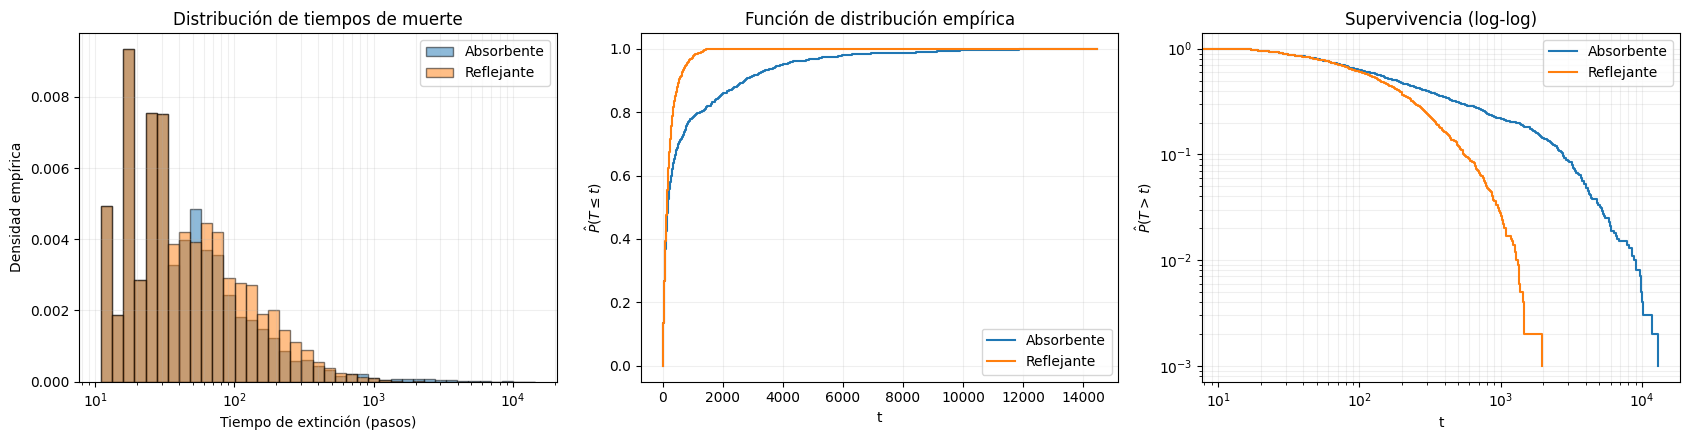

In [ ]:
import matplotlib.pyplot as plt
distribuciones = {"Absorbente": T_abs, "Reflejante": T_ref}

obs = {k: T[np.isfinite(T)] for k, T in distribuciones.items()}
t_max = max(o.max() for o in obs.values() if len(o))
t_min = max(min(o.min() for o in obs.values() if len(o)), 1)
if t_max <= t_min:
    t_max = t_min + 1

for name, T in distribuciones.items():
    o = obs[name]
    print(f"{name}: extinciones {len(o)}/{len(T)} | censuradas {len(T) - len(o)} | "
          f"media {o.mean():.1f} | mediana {np.median(o):.1f} | máx {o.max():.0f}")

bins = np.geomspace(t_min, t_max, 40)
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(17, 4.5))

for name, T in distribuciones.items():
    o = obs[name]; N = len(T)
    t = np.unique(np.r_[0, o, t_max])
    F = np.searchsorted(np.sort(o), t, side="right") / N
    S = 1 - F

    ax1.hist(o, bins=bins, density=True, alpha=0.5, edgecolor="black", label=name)
    ax2.step(t, F, where="post", label=name)
    m = S > 0
    ax3.step(t[m], S[m], where="post", label=name)

ax1.set_xscale("log")
ax1.set_xlabel("Tiempo de extinción (pasos)"); ax1.set_ylabel("Densidad empírica")
ax1.set_title("Distribución de tiempos de muerte")
ax2.set_xlabel("t"); ax2.set_ylabel(r"$\hat P(T\leq t)$")
ax2.set_title("Función de distribución empírica")
ax3.set_xscale("log"); ax3.set_yscale("log")
ax3.set_xlabel("t"); ax3.set_ylabel(r"$\hat P(T>t)$")
ax3.set_title("Supervivencia (log-log)")
for ax in (ax1, ax2, ax3):
    ax.legend(); ax.grid(alpha=0.2, which="both")

plt.tight_layout(); plt.show()


In [ ]:
sim = BranchingProcessLattice(dimension=2, box=10, kill_boundary=True,
                              max_charge=None, seed=42)
sim.add_loop((-0.5, -0.5), size=5)
sim.run(max_steps=10**9, snapshot_steps=(0, 10, 100, 500), verbose=True)


Extinción en t = 33471


Estados

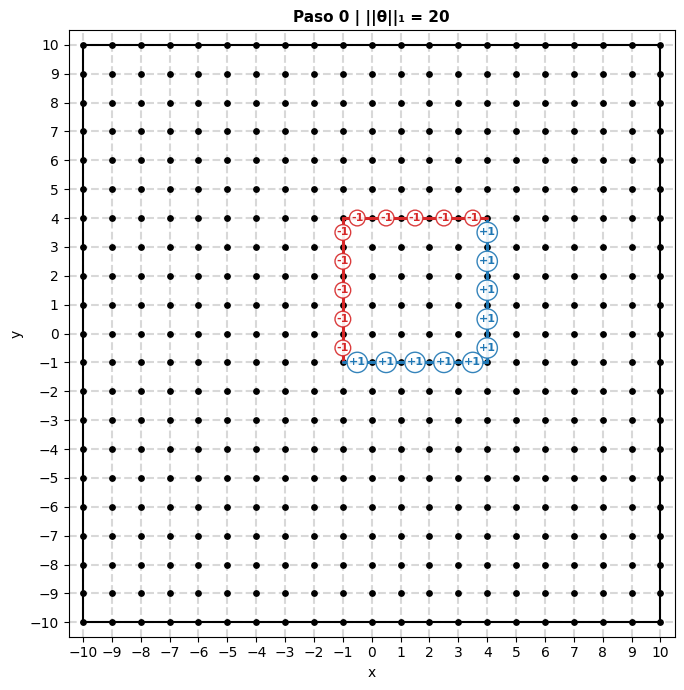

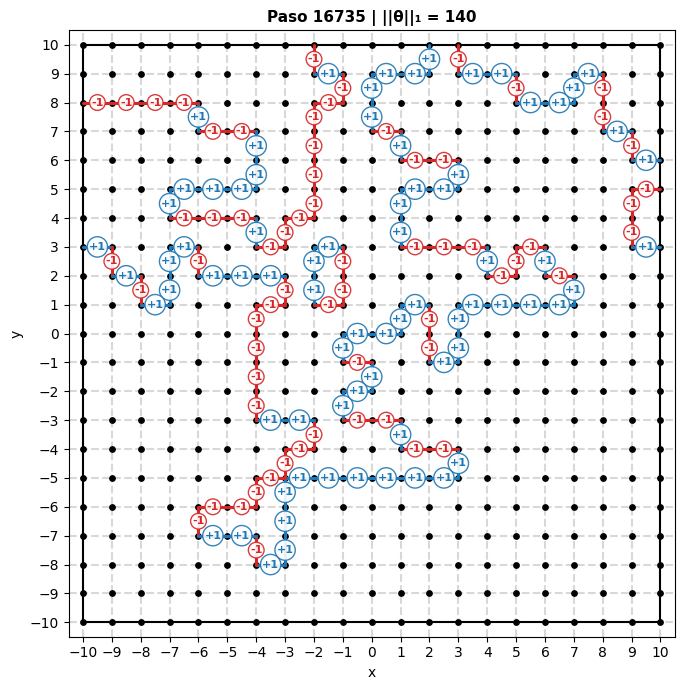

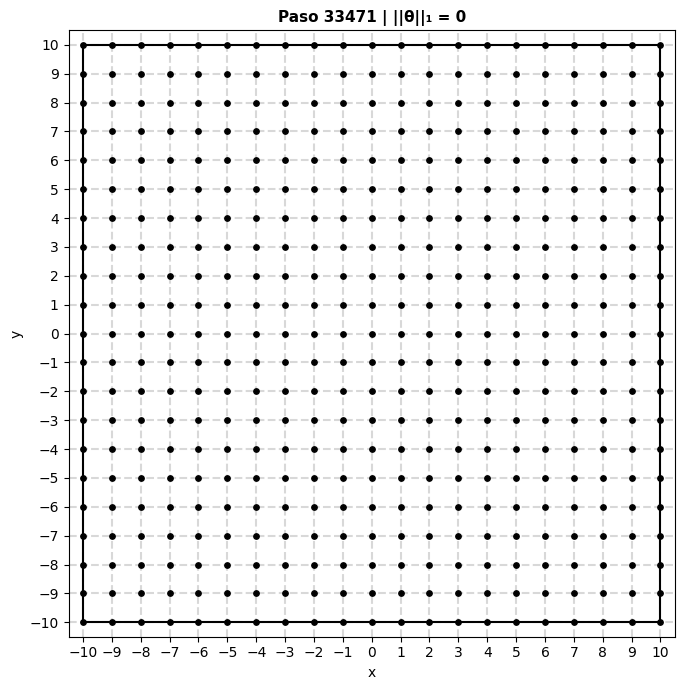

In [ ]:
n = sim.t
for k in (0, n // 2, n):
    sim.plot_state(sim.get_state(k), title=f"Paso {k}")


Experimento 3D v 2D

2d

In [ ]:
from branching_fast import experiment_grid


In [ ]:
df_2d = experiment_grid(
    dimensions=(2,),
    boundaries=("finite", "absorb", "infinite"),
    loop_sizes=(2, 3, 5, 8),
    repetitions=500,
    L=10,
    max_steps=20000,
    seed=2026,
    checkpoint_every=1000,
    checkpoint_file="branching_2D_final.csv"
)


Checkpoint guardado: 1000/6000
Checkpoint guardado: 2000/6000
Checkpoint guardado: 3000/6000
Checkpoint guardado: 4000/6000
Checkpoint guardado: 5000/6000
Checkpoint guardado: 6000/6000
Experimento terminado: 6000/6000


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def km_curve(durations, events):
    d = np.asarray(durations, float)
    e = np.asarray(events, bool)
    times = np.unique(d[e])
    S, s = [], 1.0
    for t in times:
        n = (d >= t).sum()
        k = ((d == t) & e).sum()
        s *= 1 - k / n
        S.append(s)
    return np.r_[0, times], np.r_[1, S]


def graficos_experimento(
    csv_file,
    max_steps=40_000,
    output_dir="graficos_branching"
):
    df = pd.read_csv(csv_file)
    os.makedirs(output_dir, exist_ok=True)

    boundaries = sorted(df["boundary"].unique())
    loops = sorted(df["loop_size"].unique())

    surv = (
        df.groupby(["boundary", "loop_size"])["censored"]
        .mean()
        .reset_index(name="survival")
    )

    plt.figure(figsize=(8, 5))

    for boundary in boundaries:
        sub = surv[surv["boundary"] == boundary]

        plt.plot(
            sub["loop_size"],
            sub["survival"],
            marker="o",
            label=boundary
        )

    plt.xlabel("Tamaño del loop")
    plt.ylabel(fr"$\hat P(T>{max_steps})$")
    plt.title("Supervivencia al tiempo de censura")
    plt.legend()
    plt.grid(alpha=0.2)
    plt.tight_layout()

    plt.savefig(
        f"{output_dir}/supervivencia_censura.png",
        dpi=300
    )
    plt.show()


    fig, axes = plt.subplots(
        1,
        len(loops),
        figsize=(4 * len(loops), 4),
        sharey=True
    )

    if len(loops) == 1:
        axes = [axes]

    for ax, loop in zip(axes, loops):

        for boundary in boundaries:
            sub = df[
                (df["loop_size"] == loop) &
                (df["boundary"] == boundary)
            ]

            durations = sub["T"].fillna(max_steps)
            events = ~sub["censored"]

            x, y = km_curve(durations, events)
            ax.step(x, y, where="post", label=boundary)

        ax.legend()
        ax.set_title(f"Loop {loop}")
        ax.set_xlabel("Pasos")
        ax.grid(alpha=0.2)

    axes[0].set_ylabel(r"$\hat P(T>t)$")

    fig.suptitle(
        "Curvas de supervivencia",
        y=1.02
    )

    plt.tight_layout()

    plt.savefig(
        f"{output_dir}/kaplan_meier.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()


    radius = (
        df.groupby(["boundary", "loop_size"])["max_radius"]
        .agg(["mean", "std", "count"])
        .reset_index()
    )

    radius["se"] = (
        radius["std"]
        / np.sqrt(radius["count"])
    )

    plt.figure(figsize=(8, 5))

    for boundary in boundaries:
        sub = radius[
            radius["boundary"] == boundary
        ]

        plt.errorbar(
            sub["loop_size"],
            sub["mean"],
            yerr=1.96 * sub["se"],
            marker="o",
            capsize=3,
            label=boundary
        )

    plt.xlabel("Tamaño del loop")
    plt.ylabel("Radio máximo")
    plt.title("Expansión espacial máxima")
    plt.legend()
    plt.grid(alpha=0.2)
    plt.tight_layout()

    plt.savefig(
        f"{output_dir}/radio_maximo.png",
        dpi=300
    )
    plt.show()


    particles = (
        df.groupby(["boundary", "loop_size"])["max_particles"]
        .agg(["mean", "std", "count"])
        .reset_index()
    )

    particles["se"] = (
        particles["std"]
        / np.sqrt(particles["count"])
    )

    plt.figure(figsize=(8, 5))

    for boundary in boundaries:
        sub = particles[
            particles["boundary"] == boundary
        ]

        plt.errorbar(
            sub["loop_size"],
            sub["mean"],
            yerr=1.96 * sub["se"],
            marker="o",
            capsize=3,
            label=boundary
        )

    plt.xlabel("Tamaño del loop")
    plt.ylabel("Máximo número de partículas")
    plt.title("Crecimiento máximo del proceso")
    plt.legend()
    plt.grid(alpha=0.2)
    plt.tight_layout()

    plt.savefig(
        f"{output_dir}/max_particulas.png",
        dpi=300
    )
    plt.show()


    area = (
        df.groupby(["boundary", "loop_size"])["area_particles"]
        .agg(["mean", "median"])
        .reset_index()
    )

    plt.figure(figsize=(8, 5))

    for boundary in boundaries:
        sub = area[
            area["boundary"] == boundary
        ]

        plt.plot(
            sub["loop_size"],
            sub["median"],
            marker="o",
            label=boundary
        )

    plt.yscale("log")

    plt.xlabel("Tamaño del loop")
    plt.ylabel(r"Mediana de $\sum_t N_t$")
    plt.title("Actividad acumulada del proceso")
    plt.legend()
    plt.grid(alpha=0.2, which="both")
    plt.tight_layout()

    plt.savefig(
        f"{output_dir}/area_particulas.png",
        dpi=300
    )
    plt.show()


    resumen = (
        df.groupby(["boundary", "loop_size"])
        .agg(
            n=("censored", "size"),
            survival=(
                "censored",
                "mean"
            ),
            median_T=("T", "median"),
            mean_max_radius=("max_radius", "mean"),
            mean_max_particles=("max_particles", "mean"),
            median_area=("area_particles", "median")
        )
        .reset_index()
    )

    print("\n--- RESUMEN ---")
    print(resumen.to_string(index=False))

    resumen.to_csv(
        f"{output_dir}/resumen.csv",
        index=False
    )

    return resumen


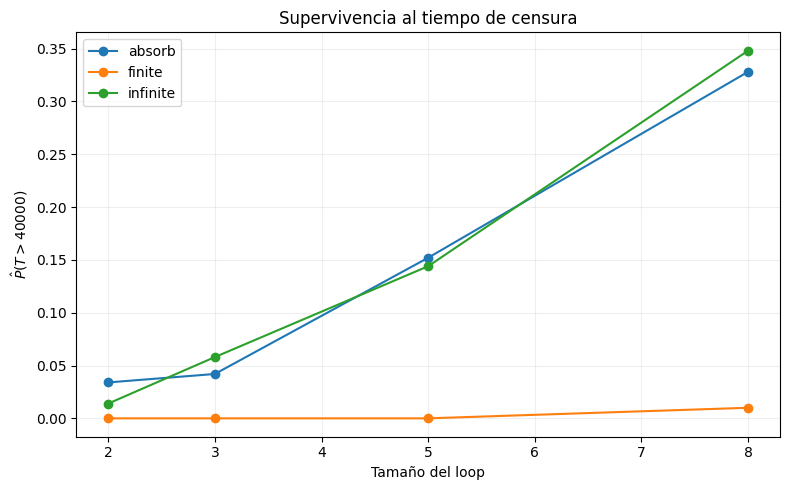

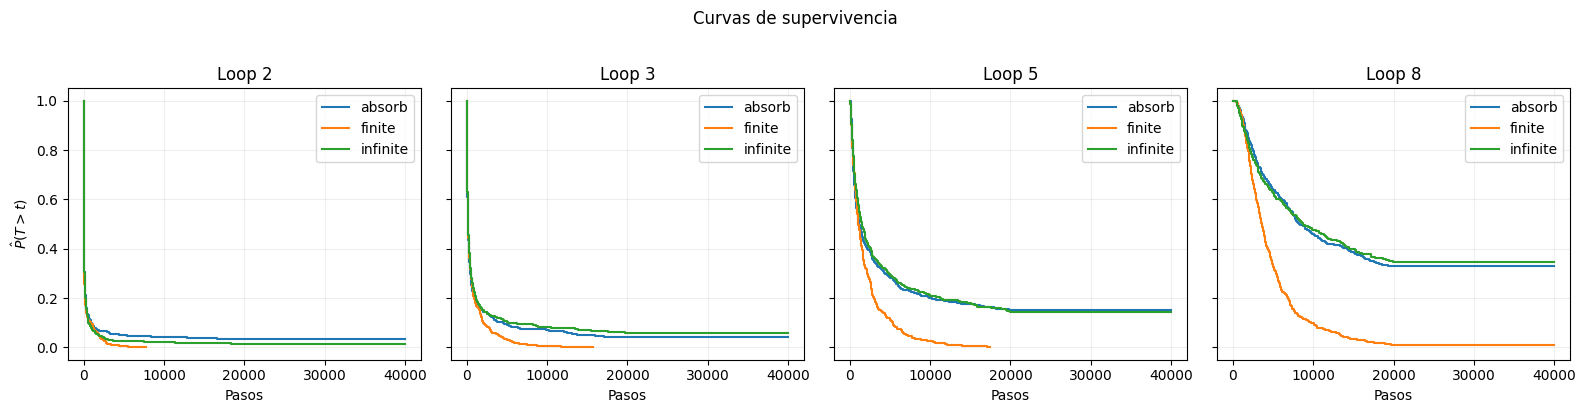

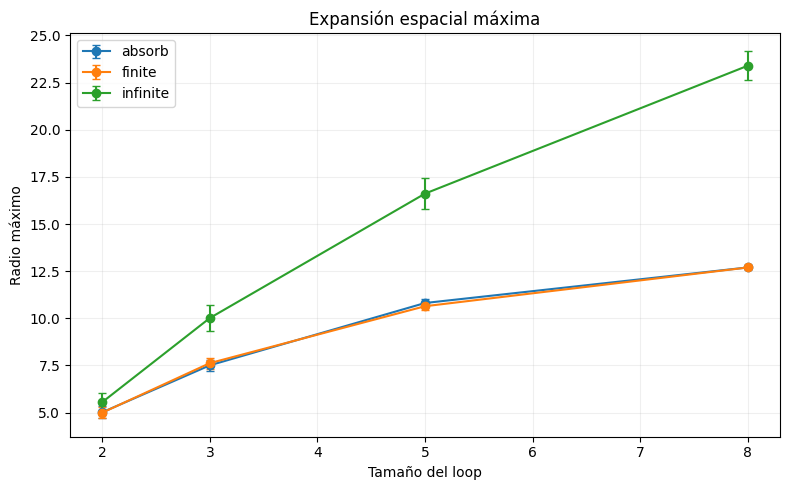

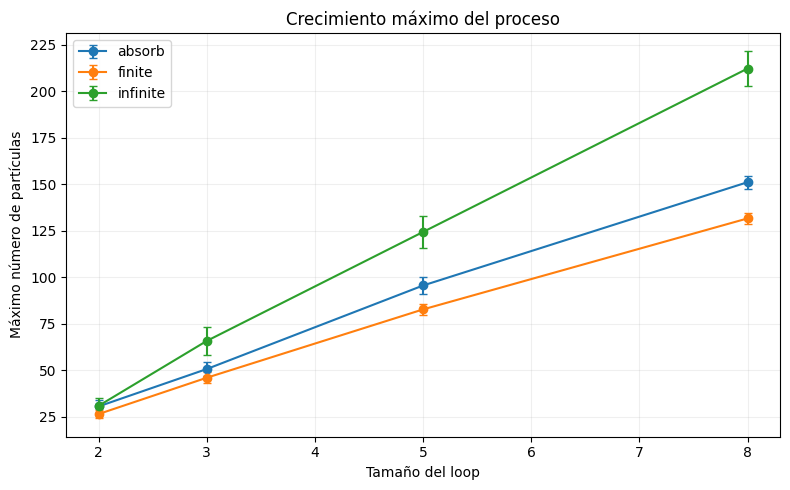

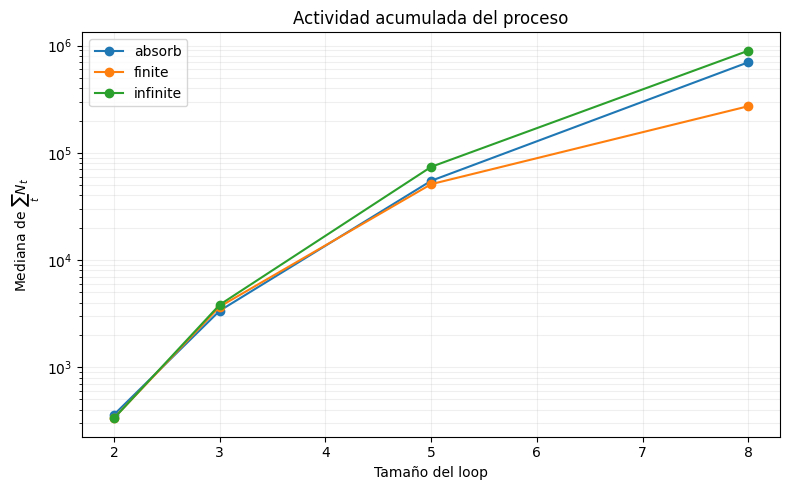


--- RESUMEN ---
boundary  loop_size   n  survival  median_T  mean_max_radius  mean_max_particles  median_area
  absorb          2 500     0.034      34.0         5.014784              30.482        360.0
  absorb          3 500     0.042     155.0         7.506038              50.596       3360.0
  absorb          5 500     0.152     804.0        10.810091              95.548      54753.0
  absorb          8 500     0.328    4556.0        12.695978             151.120     698817.0
  finite          2 500     0.000      32.0         4.993820              26.380        335.0
  finite          3 500     0.000     190.0         7.622004              45.916       3669.0
  finite          5 500     0.000    1058.0        10.639737              82.684      50926.0
  finite          8 500     0.010    3574.0        12.693403             131.640     271902.0
infinite          2 500     0.014      32.0         5.554639              30.804        333.0
infinite          3 500     0.058     159.0

In [ ]:
resumen = graficos_experimento(
    "branching_2D_final.csv",
    max_steps=40_000
)


In [ ]:
df_3d_ext = experiment_grid(
    dimensions=(3,),
    boundaries=("finite",),
    loop_sizes=(1,),
    repetitions=50,
    L=3,
    max_steps=20_000,
    seed=2026,
    checkpoint_every=10,
    checkpoint_file="branching_3D_extincion.csv"
)


Checkpoint guardado: 10/50
Checkpoint guardado: 20/50
Checkpoint guardado: 30/50
Checkpoint guardado: 40/50
Checkpoint guardado: 50/50
Experimento terminado: 50/50


In [ ]:
df_ext = pd.read_csv("branching_3D_extincion.csv")

print(df_ext["censored"].value_counts())
print("Supervivencia:", df_ext["censored"].mean())
print("Extinciones:", (~df_ext["censored"]).sum())


censored
True     33
False    17
Name: count, dtype: int64
Supervivencia: 0.66
Extinciones: 17


variando L

In [ ]:
from branching_fast import experiment_L_3d

In [ ]:
df_3d_L = experiment_L_3d(
    L_values=(3, 5, 7, 10),
    repetitions=50,
    loop_size=1,
    max_steps=20_000,
    seed=2028,
    checkpoint_every=5,
    checkpoint_file="branching_3D_L.csv"
)


Checkpoint guardado: 5/200
Checkpoint guardado: 10/200
Checkpoint guardado: 15/200
Checkpoint guardado: 20/200
Checkpoint guardado: 25/200
Checkpoint guardado: 30/200
Checkpoint guardado: 35/200
Checkpoint guardado: 40/200
Checkpoint guardado: 45/200
Checkpoint guardado: 50/200
Checkpoint guardado: 55/200
Checkpoint guardado: 60/200
Checkpoint guardado: 65/200
Checkpoint guardado: 70/200
Checkpoint guardado: 75/200
Checkpoint guardado: 80/200
Checkpoint guardado: 85/200
Checkpoint guardado: 90/200
Checkpoint guardado: 95/200
Checkpoint guardado: 100/200
Checkpoint guardado: 105/200
Checkpoint guardado: 110/200
Checkpoint guardado: 115/200
Checkpoint guardado: 120/200
Checkpoint guardado: 125/200
Checkpoint guardado: 130/200
Checkpoint guardado: 135/200
Checkpoint guardado: 140/200
Checkpoint guardado: 145/200
Checkpoint guardado: 150/200
Checkpoint guardado: 155/200
Checkpoint guardado: 160/200
Checkpoint guardado: 165/200
Checkpoint guardado: 170/200
Checkpoint guardado: 175/200
Check

In [ ]:
resumen_L = (
    df_3d_L.groupby("L")
    .agg(
        n=("censored", "size"),
        survival_20000=("censored", "mean"),
        extinctions=("censored", lambda x: (~x).sum()),
        mean_max_particles=("max_particles", "mean"),
        mean_max_radius=("max_radius", "mean")
    )
)

print(resumen_L)


     n  survival_20000  extinctions  mean_max_particles  mean_max_radius
L                                                                       
3   50            0.56           22              273.00         3.329144
5   50            0.62           19             1192.08         5.629039
7   50            0.62           19             2530.08         7.815167
10  50            0.68           16             3835.92        10.190140


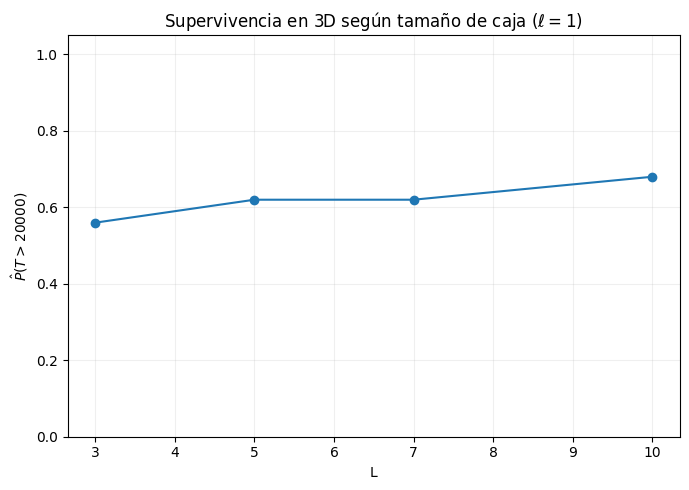

In [ ]:
surv_L = (
    df_3d_L.groupby("L")["censored"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(7, 5))

plt.plot(
    surv_L["L"],
    surv_L["censored"],
    marker="o"
)

plt.xlabel("L")
plt.ylabel(r"$\hat P(T>20000)$")
plt.title(r"Supervivencia en 3D según tamaño de caja ($\ell=1$)")
plt.ylim(0, 1.05)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


In [ ]:
from branching_fast import run_long_trajectory


In [ ]:
import numpy as np
from scipy.optimize import minimize
from scipy.special import erfc
from scipy.stats import chi2

assert "BranchingProcessLattice" in globals(), \
    "Define primero BranchingProcessLattice (celda de la clase) y usa %run -i"


def nuevo_sim(boundary="absorb", L=5, loop_size=3, seed=None, d=2, plane=(0, 1)):
    sim = BranchingProcessLattice(dimension=d, box=L, boundary=boundary,
                                  max_charge=None, seed=seed)
    x0 = -(loop_size // 2)
    c = [0.0] * d
    c[plane[0]] = x0 + 0.5
    c[plane[1]] = x0 + 0.5
    sim.add_loop(tuple(c), size=loop_size)
    return sim


def _changes(sim, theta, e, boundary, sgn):
    c = boundary[e]
    out = {}
    for b, cb in boundary.items():
        old = theta.get(b, 0)
        new = old - sgn * c * cb
        if sim.kill_boundary and sim._is_boundary_edge(b):
            new = 0
        if sim.max_charge is not None:
            new = max(-sim.max_charge, min(sim.max_charge, new))
        out[b] = (old, new)
    return out


def step_u(sim, u1, u2):
    th = sim.theta
    if not th:
        return None
    edges = sorted(th)
    w = np.cumsum([abs(th[e]) for e in edges])
    e = edges[min(int(np.searchsorted(w, u1 * w[-1], side="right")), len(edges) - 1)]
    sgn = 1 if th[e] > 0 else -1
    faces = sim.get_adjacent_faces(e)
    f, boundary = faces[min(int(u2 * len(faces)), len(faces) - 1)]
    for b, (old, new) in _changes(sim, th, e, boundary, sgn).items():
        sim._update_edge(b, new)
    if sim.infinite and any(b in sim.theta and sim._is_boundary_edge(b) for b in boundary):
        sim._grow()
    return e, f, sgn, boundary[e]


def simular_T(boundary, n=500, L=5, loop_size=3, max_steps=200000, seed=0):
    rng = np.random.default_rng(seed)
    T = np.full(n, np.nan)
    for r in range(n):
        sim = nuevo_sim(boundary, L, loop_size)
        for t in range(max_steps):
            if sim._l1 == 0:
                T[r] = t
                break
            step_u(sim, *rng.random(2))
    return T



def _exp_logf(y, p):
    lam = np.exp(p[0]);  return np.log(lam) - lam * y
def _exp_logS(y, p):
    return -np.exp(p[0]) * y

def _wei_logf(y, p):
    k, s = np.exp(p[0]), np.exp(p[1])
    return np.log(k / s) + (k - 1) * np.log(y / s) - (y / s) ** k
def _wei_logS(y, p):
    k, s = np.exp(p[0]), np.exp(p[1])
    return -(y / s) ** k

def _gpd_logf(y, p):
    xi, s = p[0], np.exp(p[1])
    if abs(xi) < 1e-8:
        return -np.log(s) - y / s
    t = 1 + xi * y / s
    return np.where(t > 0, -np.log(s) - (1 / xi + 1) * np.log(np.where(t > 0, t, 1)), -np.inf)
def _gpd_logS(y, p):
    xi, s = p[0], np.exp(p[1])
    if abs(xi) < 1e-8:
        return -y / s
    t = 1 + xi * y / s
    return np.where(t > 0, -(1 / xi) * np.log(np.where(t > 0, t, 1)), -np.inf)

def _ln_logf(y, p):
    mu, s = p[0], np.exp(p[1])
    return -np.log(y * s * np.sqrt(2 * np.pi)) - (np.log(y) - mu) ** 2 / (2 * s * s)
def _ln_logS(y, p):
    mu, s = p[0], np.exp(p[1])
    return np.log(0.5 * erfc((np.log(y) - mu) / (s * np.sqrt(2))) + 1e-300)

_MODELOS = {
    "exp":       dict(npar=1, logf=_exp_logf, logS=_exp_logS,
                      nombre="Exponencial     (lambda)"),
    "weibull":   dict(npar=2, logf=_wei_logf, logS=_wei_logS,
                      nombre="Weibull         (forma k, escala)"),
    "gpd":       dict(npar=2, logf=_gpd_logf, logS=_gpd_logS,
                      nombre="Pareto general. (forma xi, escala)"),
    "lognormal": dict(npar=2, logf=_ln_logf, logS=_ln_logS,
                      nombre="Log-normal      (mu, sigma)"),
}


def _nll(p, m, y_ev, n_cens, c):
    try:
        with np.errstate(all="ignore"):
            ll = np.sum(m["logf"](y_ev, p))
            if n_cens:
                ll += n_cens * float(m["logS"](np.array([c]), p)[0])
        return 1e12 if not np.isfinite(ll) else -ll
    except Exception:
        return 1e12


def _ajusta(nombre, y_ev, n_cens, c, lam0):
    m = _MODELOS[nombre]
    if nombre == "exp":
        starts = [[np.log(lam0)]]
    elif nombre == "weibull":
        starts = [[0.0, np.log(1 / lam0)], [np.log(0.7), np.log(1 / lam0)]]
    elif nombre == "gpd":
        starts = [[x, np.log(1 / lam0)] for x in (-0.2, 0.01, 0.3)]
    else:
        starts = [[np.log(np.mean(y_ev)), 0.0], [np.log(np.median(y_ev)), np.log(1.5)]]
    best = None
    for x0 in starts:
        r = minimize(_nll, x0, args=(m, y_ev, n_cens, c), method="Nelder-Mead",
                     options=dict(xatol=1e-9, fatol=1e-10, maxiter=4000))
        if best is None or r.fun < best.fun:
            best = r
    return best


def _desc_params(nombre, p):
    if nombre == "exp":
        return f"lambda={np.exp(p[0]):.3e}"
    if nombre == "weibull":
        return f"k={np.exp(p[0]):.3f}, escala={np.exp(p[1]):.1f}"
    if nombre == "gpd":
        return f"xi={p[0]:+.3f}, escala={np.exp(p[1]):.1f}"
    return f"mu={p[0]:.3f}, sigma={np.exp(p[1]):.3f}"


def ajuste_cola(T, max_steps, qs=(0.5, 0.75), modelos=("exp", "weibull", "gpd", "lognormal"),
                plot=True, label=""):
    T = np.asarray(T, float)
    cens = ~np.isfinite(T)
    obs = np.where(cens, max_steps, T)
    fin = T[~cens]
    print(f"{label}  n={len(T)}  censuradas={cens.sum()}  media(obs)={fin.mean():.1f}  mediana={np.median(fin):.1f}")
    res = {}
    for q in qs:
        u = np.quantile(fin, q)
        m = obs > u
        y = obs[m] - u
        c_ = ~cens[m]
        y_ev, n_cens, c = y[c_], int((~c_).sum()), max_steps - u
        d = len(y_ev)
        if d < 8:
            print(f"  u=q{q:.2f}: solo {d} excesos, se omite")
            continue
        lam0 = d / y.sum()
        print(f"\n  u = q{q:.2f} = {u:.1f}   excesos = {d} (+{n_cens} censurados)")
        fits = {}
        for nm in modelos:
            r = _ajusta(nm, y_ev, n_cens, c, lam0)
            fits[nm] = dict(p=r.x, ll=-r.fun, aic=2 * _MODELOS[nm]["npar"] + 2 * r.fun)
        aic_min = min(f["aic"] for f in fits.values())
        for nm, f in fits.items():
            print(f"    {_MODELOS[nm]['nombre']:36s} {_desc_params(nm, f['p']):34s} "
                  f"logL={f['ll']:9.2f}  AIC={f['aic']:9.2f}  dAIC={f['aic']-aic_min:6.2f}")
        if "exp" in fits:
            for otro, que in (("weibull", "k=1"), ("gpd", "xi=0")):
                if otro in fits:
                    lr = max(0.0, 2 * (fits[otro]["ll"] - fits["exp"]["ll"]))
                    print(f"    LRT exponencial vs {otro:7s} ({que}):  2*dlogL={lr:6.2f}   p={chi2.sf(lr, 1):.3f}")
        res[q] = dict(u=u, n_exc=d, n_cens=n_cens, fits=fits)

        if plot:
            import matplotlib.pyplot as plt
            plt.figure(figsize=(6, 4))
            ys = np.sort(y_ev)
            grid = np.linspace(1e-3, ys.max(), 200)
            S_emp = [np.mean(y > t) for t in ys]
            plt.semilogy(ys, S_emp, "k.", ms=4, label="empírica")
            for nm, f in fits.items():
                plt.semilogy(grid, np.exp(_MODELOS[nm]["logS"](grid, f["p"])), lw=1.2, label=nm)
            plt.ylim(max(1e-3, 0.5 / len(y)), 1.05)
            plt.xlabel(f"exceso  t - u   (u={u:.0f})"); plt.ylabel("P(T-u > t | T>u)")
            plt.title(f"{label}  cola desde q{q:.2f}"); plt.legend(); plt.grid(alpha=.3, which="both")
            plt.show()
    return res


def par_acoplado(L=5, loop_size=3, max_steps=200000, rng=None, d=2):
    rng = rng or np.random.default_rng()
    sa = nuevo_sim("absorb", L, loop_size, d=d)
    sr = nuevo_sim("reflect", L, loop_size, d=d)
    Ta = Tr = split = None
    U, k = rng.random((4096, 2)), 0
    for t in range(max_steps + 1):
        if Ta is None and sa._l1 == 0:
            Ta = t
        if Tr is None and sr._l1 == 0:
            Tr = t
        if Ta is not None and Tr is not None:
            break
        if k == len(U):
            U, k = rng.random((4096, 2)), 0
        u1, u2 = U[k]; k += 1
        if Ta is None:
            step_u(sa, u1, u2)
        if Tr is None:
            step_u(sr, u1, u2)
        if split is None and sa.theta != sr.theta:
            split = t + 1
    return (np.nan if Ta is None else Ta,
            np.nan if Tr is None else Tr,
            np.nan if split is None else split)


def experimento_acople(n=500, L=5, loop_size=3, max_steps=200000, seed=0, plot=True):
    rng = np.random.default_rng(seed)
    R = np.array([par_acoplado(L, loop_size, max_steps, rng) for _ in range(n)])
    Ta, Tr, S = R.T
    ok = np.isfinite(Ta) & np.isfinite(Tr)
    Ta, Tr, S = Ta[ok], Tr[ok], S[ok]
    dif = Ta - Tr
    se_p = dif.std(ddof=1) / np.sqrt(len(dif))
    se_i = np.sqrt((Ta.var(ddof=1) + Tr.var(ddof=1)) / len(dif))
    sep = np.isfinite(S)
    print(f"n válidos = {ok.sum()}/{n}")
    print(f"E[T_abs]={Ta.mean():.1f}  E[T_ref]={Tr.mean():.1f}   diferencia = {dif.mean():+.1f} ± {se_p:.1f}")
    print(f"medianas: T_abs={np.median(Ta):.0f}  T_ref={np.median(Tr):.0f}")
    print(f"corr(T_abs,T_ref) = {np.corrcoef(Ta, Tr)[0,1]:.3f}")
    print(f"SE de la diferencia: pareada {se_p:.1f} vs independiente {se_i:.1f}  (ganancia x{(se_i/se_p)**2:.2f} en varianza)")
    if sep.any():
        print(f"separación: {sep.sum()}/{len(S)} corridas ({100*sep.mean():.0f}%), mediana en el paso {np.median(S[sep]):.0f}")
        print(f"            en las {(~sep).sum()} corridas restantes la frontera no influyó (T_abs = T_ref)")
    else:
        print("nunca se separaron")
    if plot:
        import matplotlib.pyplot as plt
        plt.figure(figsize=(4.8, 4.6))
        plt.loglog(Tr + 1, Ta + 1, ".", ms=4, alpha=.6)
        lim = [1, max(Ta.max(), Tr.max()) + 1]
        plt.loglog(lim, lim, "k--", lw=1)
        plt.xlabel("T reflejante + 1"); plt.ylabel("T absorbente + 1")
        plt.title("pares acoplados"); plt.grid(alpha=.3, which="both"); plt.show()
    return Ta, Tr, S

from branching_fast import simular_T, experimento_acople


absorbente  n=500  censuradas=0  media(obs)=859.7  mediana=177.0

  u = q0.50 = 177.0   excesos = 250 (+0 censurados)
    Exponencial     (lambda)             lambda=6.764e-04                   logL= -2074.67  AIC=  4151.34  dAIC= 54.94
    Weibull         (forma k, escala)    k=0.708, escala=1183.2             logL= -2046.20  AIC=  4096.40  dAIC=  0.00
    Pareto general. (forma xi, escala)   xi=+0.579, escala=769.7            logL= -2056.25  AIC=  4116.50  dAIC= 20.10
    Log-normal      (mu, sigma)          mu=6.266, sigma=1.726              logL= -2057.71  AIC=  4119.42  dAIC= 23.02
    LRT exponencial vs weibull (k=1):  2*dlogL= 56.94   p=0.000
    LRT exponencial vs gpd     (xi=0):  2*dlogL= 36.84   p=0.000


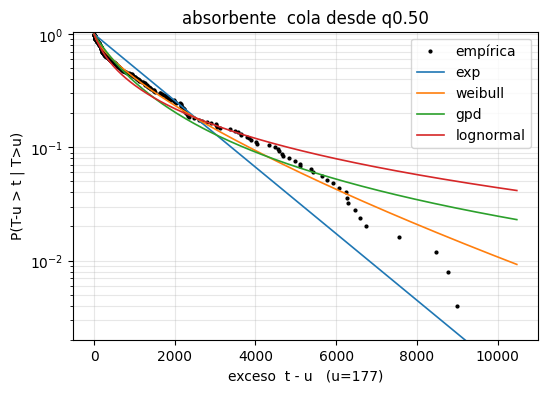


  u = q0.75 = 822.5   excesos = 125 (+0 censurados)
    Exponencial     (lambda)             lambda=4.779e-04                   logL= -1080.76  AIC=  2163.51  dAIC=  0.00
    Weibull         (forma k, escala)    k=0.971, escala=2066.2             logL= -1080.67  AIC=  2165.34  dAIC=  1.83
    Pareto general. (forma xi, escala)   xi=-0.025, escala=2144.4           logL= -1080.73  AIC=  2165.46  dAIC=  1.95
    Log-normal      (mu, sigma)          mu=7.034, sigma=1.322              logL= -1091.49  AIC=  2186.99  dAIC= 23.47
    LRT exponencial vs weibull (k=1):  2*dlogL=  0.17   p=0.678
    LRT exponencial vs gpd     (xi=0):  2*dlogL=  0.05   p=0.825


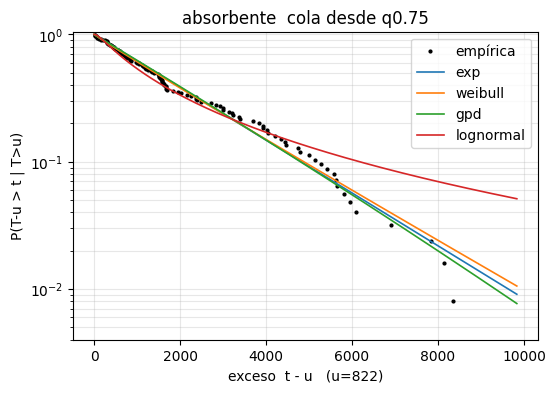

reflejante  n=500  censuradas=0  media(obs)=197.0  mediana=119.0

  u = q0.50 = 119.0   excesos = 247 (+0 censurados)
    Exponencial     (lambda)             lambda=4.630e-03                   logL= -1574.67  AIC=  3151.33  dAIC=  0.16
    Weibull         (forma k, escala)    k=0.930, escala=208.9              logL= -1573.59  AIC=  3151.18  dAIC=  0.00
    Pareto general. (forma xi, escala)   xi=+0.052, escala=204.8            logL= -1574.42  AIC=  3152.85  dAIC=  1.67
    Log-normal      (mu, sigma)          mu=4.721, sigma=1.339              logL= -1588.70  AIC=  3181.40  dAIC= 30.22
    LRT exponencial vs weibull (k=1):  2*dlogL=  2.16   p=0.142
    LRT exponencial vs gpd     (xi=0):  2*dlogL=  0.48   p=0.487


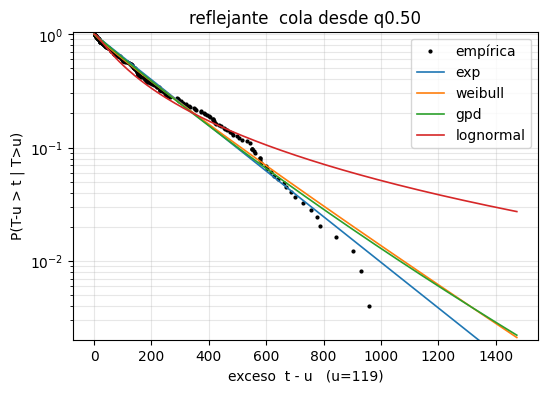


  u = q0.75 = 257.5   excesos = 125 (+0 censurados)
    Exponencial     (lambda)             lambda=4.307e-03                   logL=  -805.94  AIC=  1613.89  dAIC=  0.00
    Weibull         (forma k, escala)    k=0.952, escala=227.4              logL=  -805.71  AIC=  1615.41  dAIC=  1.53
    Pareto general. (forma xi, escala)   xi=-0.051, escala=244.2            logL=  -805.80  AIC=  1615.60  dAIC=  1.71
    Log-normal      (mu, sigma)          mu=4.797, sigma=1.380              logL=  -817.34  AIC=  1638.68  dAIC= 24.79
    LRT exponencial vs weibull (k=1):  2*dlogL=  0.47   p=0.491
    LRT exponencial vs gpd     (xi=0):  2*dlogL=  0.29   p=0.590


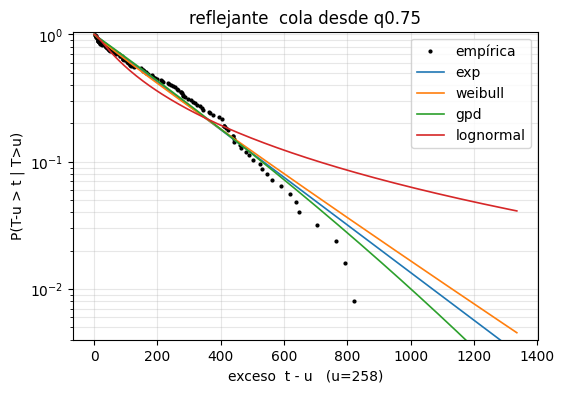

n válidos = 500/500
E[T_abs]=816.3  E[T_ref]=247.5   diferencia = +568.8 ± 61.5
medianas: T_abs=205  T_ref=156
corr(T_abs,T_ref) = 0.243
SE de la diferencia: pareada 61.5 vs independiente 64.4  (ganancia x1.10 en varianza)
separación: 380/500 corridas (76%), mediana en el paso 42
            en las 120 corridas restantes la frontera no influyó (T_abs = T_ref)


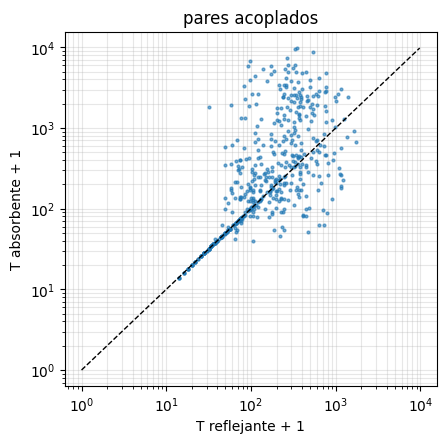

In [ ]:
MAXS = 200000

T_abs = simular_T("absorb",  n=500, L=5, loop_size=3, max_steps=MAXS, seed=1)
T_ref = simular_T("reflect", n=500, L=5, loop_size=3, max_steps=MAXS, seed=2)

ajuste_cola(T_abs, MAXS, qs=(0.5, 0.75), label="absorbente")
ajuste_cola(T_ref, MAXS, qs=(0.5, 0.75), label="reflejante")

Ta, Tr, S = experimento_acople(n=500, L=5, loop_size=3)


In [ ]:
df_3d_big = experiment_grid(
    dimensions=(3,),
    boundaries=("finite", "absorb", "infinite"),
    loop_sizes=(1, 2, 3, 5, 8, 12),
    repetitions=300,
    L=10,
    max_steps=100_000,
    seed=2027,
    checkpoint_every=200,
    checkpoint_file="branching_3D_grande.csv",
    n_jobs=None
)


Checkpoint guardado: 200/5400
Checkpoint guardado: 400/5400
Checkpoint guardado: 600/5400
Checkpoint guardado: 800/5400
Checkpoint guardado: 1000/5400
Checkpoint guardado: 1200/5400
Checkpoint guardado: 1400/5400
Checkpoint guardado: 1600/5400
Checkpoint guardado: 1800/5400
Checkpoint guardado: 2000/5400
Checkpoint guardado: 2200/5400
Checkpoint guardado: 2400/5400
Checkpoint guardado: 2600/5400
Checkpoint guardado: 2800/5400
Checkpoint guardado: 3000/5400
Checkpoint guardado: 3200/5400
Checkpoint guardado: 3400/5400
Checkpoint guardado: 3600/5400
Checkpoint guardado: 3800/5400
Checkpoint guardado: 4000/5400
Checkpoint guardado: 4200/5400
Checkpoint guardado: 4400/5400
Checkpoint guardado: 4600/5400
Checkpoint guardado: 4800/5400
Checkpoint guardado: 5000/5400
Checkpoint guardado: 5200/5400
Checkpoint guardado: 5400/5400
Experimento terminado: 5400/5400


In [ ]:
print(df_3d_big.shape)
display(df_3d_big.head())

resumen = (
    df_3d_big.groupby(["boundary", "loop_size"])
    .agg(
        n=("censored", "size"),
        sobrevive=("censored", "mean"),
        T_mediana=("T", "median"),
        radio_max=("max_radius", "mean"),
        part_max=("max_particles", "mean"),
        mult_max=("max_mult", "max"),
    )
    .round(3)
)
display(resumen)


(5400, 13)


,dimension,boundary,loop_size,rep,seed,T,censored,max_particles,area_particles,max_occupied,max_mult,max_radius,final_box
0,3,finite,1,0,2715249819,1.0,False,4,4,4,1,1.118034,10
1,3,finite,1,1,34383189,NaN,True,13462,922141374,11623,5,17.036725,10
2,3,finite,1,2,637781806,NaN,True,13320,911359988,11581,5,17.036725,10
3,3,finite,1,3,1657352935,NaN,True,13260,903948368,11607,5,17.036725,10
4,3,finite,1,4,1223561040,NaN,True,13288,903327778,11557,5,17.036725,10


n  sobrevive  T_mediana  radio_max   part_max  mult_max
boundary loop_size                                                           
absorb   1          300      0.630        1.0     10.489   7138.410         7
         2          300      0.973        5.0     15.504  11046.670         7
         3          300      1.000        NaN     15.881  11352.023         6
         5          300      1.000        NaN     15.882  11376.583         8
         8          300      1.000        NaN     15.881  11420.047         7
         12         300      1.000        NaN     15.882  11444.270         7
finite   1          300      0.640        1.0     11.340   8502.393         6
         2          300      0.987        5.0     16.745  13141.767         7
         3          300      1.000        NaN     16.976  13316.593         7
         5          300      1.000        NaN     16.983  13360.200         6
         8          300      1.000        NaN     17.001  13433.720         6
         12         300      1.000        NaN     17.024  13507.613         6
infinite 1          300      0.690        1.0     15.823  14588.833         7
         2          300      0.987        7.0     21.828  20836.867         7
         3          300      1.000        NaN     22.031  21152.847         6
         5          300      1.000        NaN     22.060  21222.220         6
         8          300      1.000        NaN     22.225  21606.273         6
         12         300      1.000        NaN     23.169  22761.580         6

In [ ]:
df_3d_big_2 = experiment_grid(
    dimensions=(3,),
    boundaries=("finite", "absorb"),
    loop_sizes=(1, 2),
    repetitions=300,
    L=3,
    max_steps=200_000,
    seed=2027,
    checkpoint_every=200,
    checkpoint_file="branching_3D_grande.csv",
    n_jobs=None
)


Checkpoint guardado: 200/1200
Checkpoint guardado: 400/1200
Checkpoint guardado: 600/1200
Checkpoint guardado: 800/1200
Checkpoint guardado: 1000/1200
Checkpoint guardado: 1200/1200
Experimento terminado: 1200/1200


n  sobrevive  T_mediana  radio_max  part_max  mult_max
boundary loop_size                                                          
absorb   1          300      0.653        1.0      2.900   180.627         6
         2          300      0.980        6.0      3.727   268.340         7
finite   1          300      0.640        1.0      3.620   330.307         6
         2          300      0.987        5.0      4.877   506.027         7

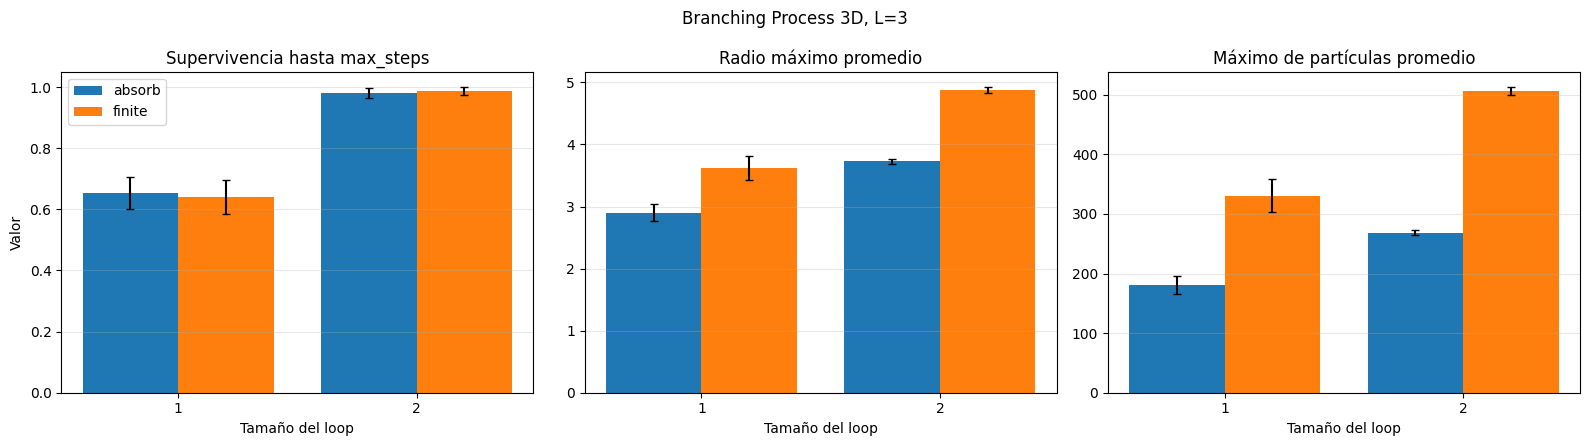

In [ ]:
resumen = (
    df_3d_big_2.groupby(["boundary", "loop_size"])
    .agg(
        n=("censored", "size"),
        sobrevive=("censored", "mean"),
        T_mediana=("T", "median"),
        radio_max=("max_radius", "mean"),
        part_max=("max_particles", "mean"),
        mult_max=("max_mult", "max"),
    )
    .round(3)
)
display(resumen)

g = df_3d_big_2.groupby(["boundary", "loop_size"])
n = g.size()
surv = g["censored"].mean()
se_surv = np.sqrt(surv * (1 - surv) / n)

metricas = [
    ("Supervivencia hasta max_steps", surv, 1.96 * se_surv),
    ("Radio máximo promedio", g["max_radius"].mean(), 1.96 * g["max_radius"].std() / np.sqrt(n)),
    ("Máximo de partículas promedio", g["max_particles"].mean(), 1.96 * g["max_particles"].std() / np.sqrt(n)),
]

bordes = sorted(df_3d_big_2["boundary"].unique())
loops = sorted(df_3d_big_2["loop_size"].unique())
ancho = 0.8 / len(bordes)
x = np.arange(len(loops))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (titulo, valores, err) in zip(axes, metricas):
    for j, b in enumerate(bordes):
        y = [valores[(b, l)] for l in loops]
        e = [err[(b, l)] for l in loops]
        ax.bar(x + j * ancho, y, ancho, yerr=e, capsize=3, label=b)
    ax.set_xticks(x + ancho * (len(bordes) - 1) / 2)
    ax.set_xticklabels(loops)
    ax.set_xlabel("Tamaño del loop")
    ax.set_title(titulo)
    ax.grid(alpha=0.3, axis="y")
axes[0].set_ylabel("Valor")
axes[0].legend()
fig.suptitle("Branching Process 3D, L=3")
plt.tight_layout()
plt.savefig("resumen_3D_L3.png", dpi=300)
plt.show()


In [ ]:
df_3d_big_3 = experiment_grid(
    dimensions=(3,),
    boundaries=("finite", "absorb","infinite"),
    loop_sizes=(1, 2, 3),
    repetitions=300,
    L=3,
    max_steps=200_000,
    seed=2027,
    checkpoint_every=200,
    checkpoint_file="branching_3D_grande_3.csv",
    n_jobs=None
)


Checkpoint guardado: 200/2700
Checkpoint guardado: 400/2700
Checkpoint guardado: 600/2700
Checkpoint guardado: 800/2700
Checkpoint guardado: 1000/2700
Checkpoint guardado: 1200/2700
Checkpoint guardado: 1400/2700
Checkpoint guardado: 1600/2700
Checkpoint guardado: 1800/2700
Checkpoint guardado: 2000/2700
Checkpoint guardado: 2200/2700
Checkpoint guardado: 2400/2700
Checkpoint guardado: 2600/2700
Experimento terminado: 2700/2700


In [ ]:
resumen = (
    df_3d_big_3.groupby(["boundary", "loop_size"])
    .agg(
        n=("censored", "size"),
        sobrevive=("censored", "mean"),
        T_mediana=("T", "median"),
        radio_max=("max_radius", "mean"),
        part_max=("max_particles", "mean"),
        mult_max=("max_mult", "max"),
    )
    .round(3)
)
display(resumen)


n  sobrevive  T_mediana  radio_max   part_max  mult_max
boundary loop_size                                                           
absorb   1          300      0.643        1.0      2.872    177.490         6
         2          300      0.990        6.0      3.750    271.107         7
         3          300      1.000        NaN      3.775    273.593         6
finite   1          300      0.640        1.0      3.620    330.307         6
         2          300      0.987        5.0      4.877    506.027         7
         3          300      1.000        NaN      4.924    512.560         6
infinite 1          300      0.630        1.0     16.682  22840.300         7
         2          300      0.973        5.0     24.908  35331.873         7
         3          300      1.000        NaN     25.505  36263.060         7

In [ ]:
import time
import numpy as np
from branching_fast import FastBranching

limite_horas = 1
bloque = 500_000

sim = make_loop_sim(dimension=3, L=3, loop_size=1, boundary="finite", seed=2026)
fs = FastBranching.from_lattice(sim, radius="linf")

ts, Ns, occ = [0], [fs.l1], [len(fs.theta)]
t0 = time.time()

def guardar():
    np.savetxt("N_vs_t.csv", np.c_[ts, Ns, occ], fmt="%d", delimiter=",",
               header="t,N,ocupadas", comments="")

try:
    while fs.l1 and (time.time() - t0) < limite_horas * 3600:
        fs.advance(bloque)
        ts.append(fs.t); Ns.append(fs.l1); occ.append(len(fs.theta))
        if len(ts) % 100 == 0:
            guardar()
            print(f"t={fs.t:,} | N={fs.l1:,} | {(time.time()-t0)/60:.1f} min")
except KeyboardInterrupt:
    print("Interrumpido")

guardar()
print("Extinción en t =", fs.t if fs.l1 == 0 else f"no ocurrió (se llegó a t={fs.t:,})")


t=49,500,000 | N=372 | 7.0 min
t=99,500,000 | N=420 | 14.5 min
t=149,500,000 | N=384 | 22.1 min
t=199,500,000 | N=424 | 29.8 min
t=249,500,000 | N=408 | 37.4 min
t=299,500,000 | N=418 | 45.0 min
t=349,500,000 | N=412 | 52.6 min
Extinción en t = no ocurrió (se llegó a t=398,500,000)


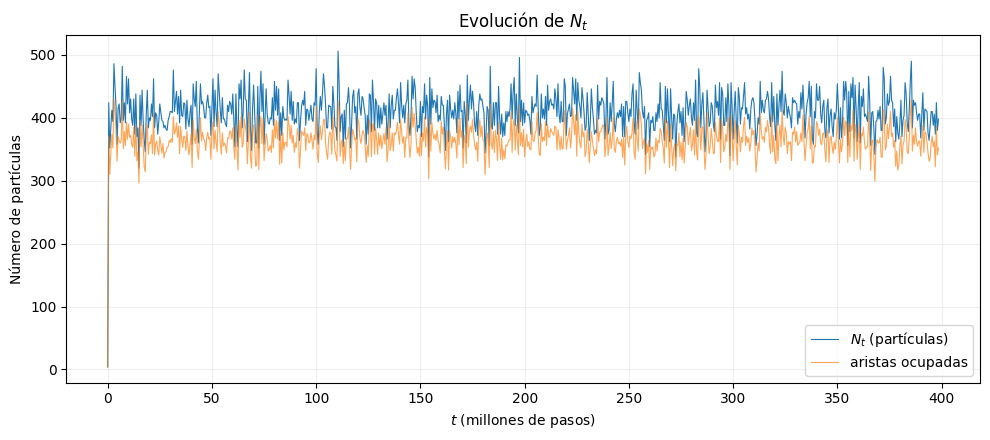

In [ ]:
import matplotlib.pyplot as plt

t = np.array(ts) / 1e6
plt.figure(figsize=(10, 4.5))
plt.plot(t, Ns, lw=0.8, label=r"$N_t$ (partículas)")
plt.plot(t, occ, lw=0.8, alpha=0.7, label="aristas ocupadas")
plt.xlabel(r"$t$ (millones de pasos)")
plt.ylabel("Número de partículas")
plt.title("Evolución de $N_t$")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig("N_vs_t.png", dpi=300)
plt.show()


Extinguidas: 3 de 300


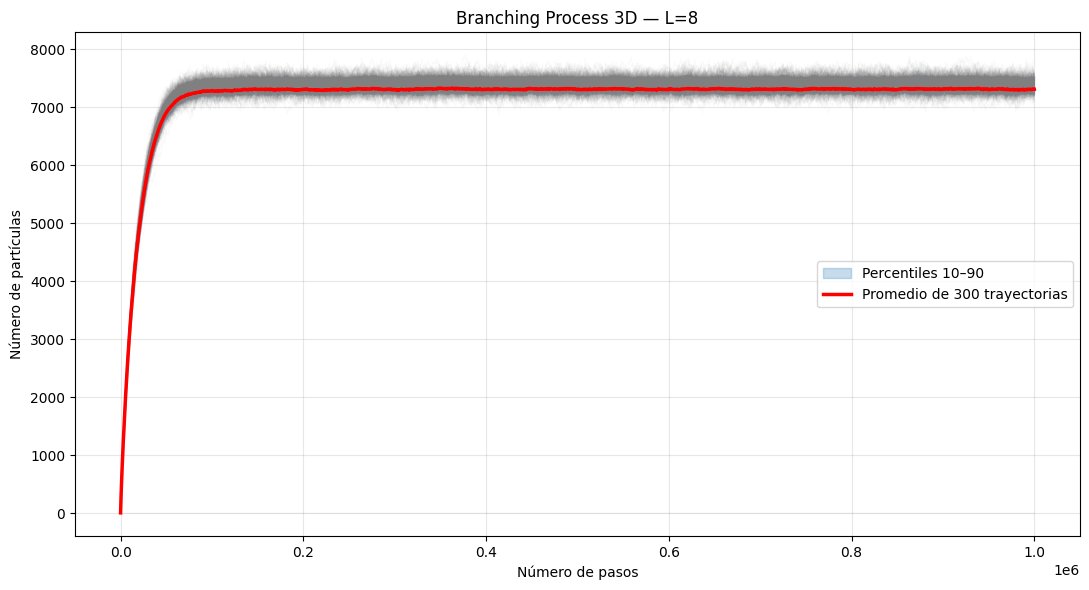

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from trayectorias_3d import correr_trayectorias

M = 300
MAX_STEPS = 1_000_000
CADA = 100
LS = (8,)

for L in LS:
    checkpoints, particulas, extinciones = correr_trayectorias(
        L, M=M, max_steps=MAX_STEPS, cada=CADA, loop_size=2
    )
    promedio = particulas.mean(axis=0)
    p10, p90 = np.percentile(particulas, [10, 90], axis=0)

    np.savez_compressed(
        f"particulas_3D_L{L}_trayectorias.npz",
        checkpoints=checkpoints,
        particulas=particulas,
        promedio=promedio,
        extinciones=extinciones
    )
    print(f"L={L}: extinguidas", np.sum(~np.isnan(extinciones)), "de", M)

    plt.figure(figsize=(11, 6))
    for tr in particulas:
        plt.plot(checkpoints, tr, alpha=0.04, linewidth=0.6, color="gray")
    plt.fill_between(checkpoints, p10, p90, color="C0", alpha=0.25, label="Percentiles 10–90")
    plt.plot(checkpoints, promedio, color="red", linewidth=2.5,
             label=f"Promedio de {M} trayectorias")
    plt.xlabel("Número de pasos")
    plt.ylabel("Número de partículas")
    plt.title(f"Branching Process 3D — L={L}")
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"particulas_3D_L{L}.png", dpi=300)
    plt.show()


L=3: extinguidas 3 de 300


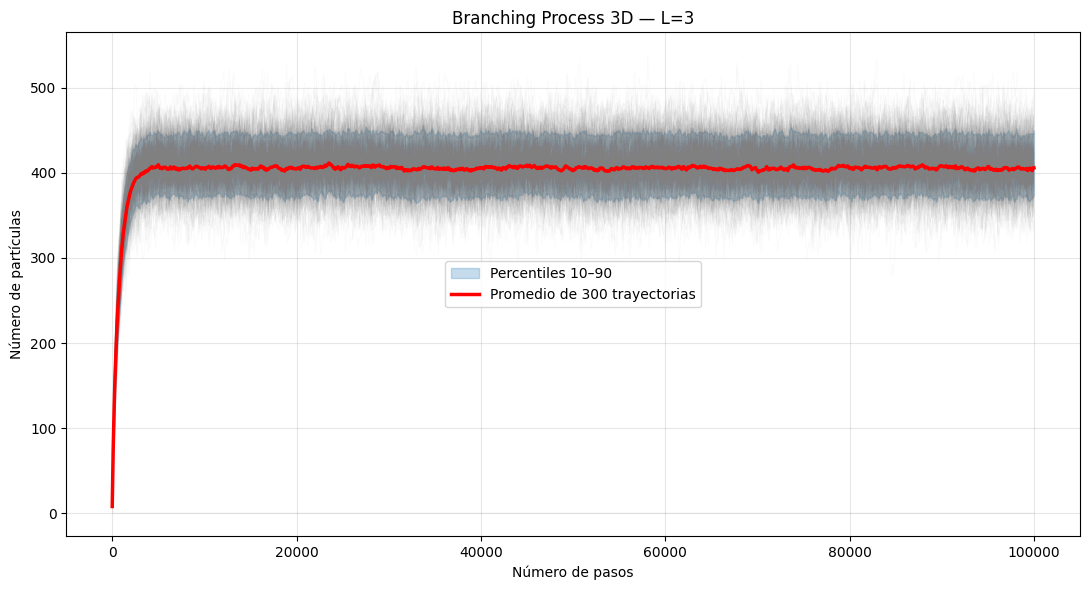

L=15: extinguidas 3 de 300


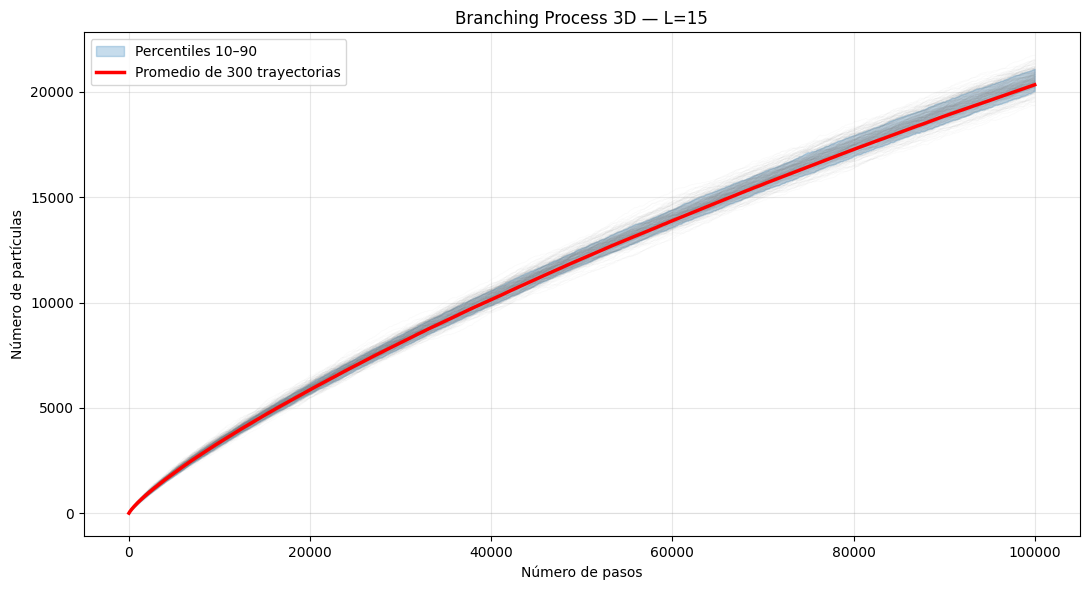

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from trayectorias_3d import correr_trayectorias

M = 300
MAX_STEPS = 100_000
CADA = 100
LS = (3, 15)

for L in LS:
    checkpoints, particulas, extinciones = correr_trayectorias(
        L, M=M, max_steps=MAX_STEPS, cada=CADA, loop_size=2
    )
    promedio = particulas.mean(axis=0)
    p10, p90 = np.percentile(particulas, [10, 90], axis=0)

    np.savez_compressed(
        f"particulas_3D_L{L}_trayectorias.npz",
        checkpoints=checkpoints,
        particulas=particulas,
        promedio=promedio,
        extinciones=extinciones
    )
    print(f"L={L}: extinguidas", np.sum(~np.isnan(extinciones)), "de", M)

    plt.figure(figsize=(11, 6))
    for tr in particulas:
        plt.plot(checkpoints, tr, alpha=0.04, linewidth=0.6, color="gray")
    plt.fill_between(checkpoints, p10, p90, color="C0", alpha=0.25, label="Percentiles 10–90")
    plt.plot(checkpoints, promedio, color="red", linewidth=2.5,
             label=f"Promedio de {M} trayectorias")
    plt.xlabel("Número de pasos")
    plt.ylabel("Número de partículas")
    plt.title(f"Branching Process 3D — L={L}")
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"particulas_3D_L{L}.png", dpi=300)
    plt.show()


In [ ]:
df_3d_big_5 = experiment_grid(
    dimensions=(3,),
    boundaries=("finite", "absorb"),
    loop_sizes=(1, 2),
    repetitions=300,
    L=2,
    max_steps=200_000,
    seed=2027,
    checkpoint_every=200,
    checkpoint_file="branching_3D_grande.csv",
    n_jobs=None
)


Checkpoint guardado: 200/1200
Checkpoint guardado: 400/1200
Checkpoint guardado: 600/1200
Checkpoint guardado: 800/1200
Checkpoint guardado: 1000/1200
Checkpoint guardado: 1200/1200
Experimento terminado: 1200/1200


n  sobrevive  T_mediana  radio_max  part_max  mult_max
boundary loop_size                                                          
absorb   1          300      0.587        1.0      1.766    50.120         6
         2          300      0.877    60648.0      2.048    73.957         6
finite   1          300      0.643        1.0      2.524   123.653         6
         2          300      0.980        6.0      3.172   185.693         6

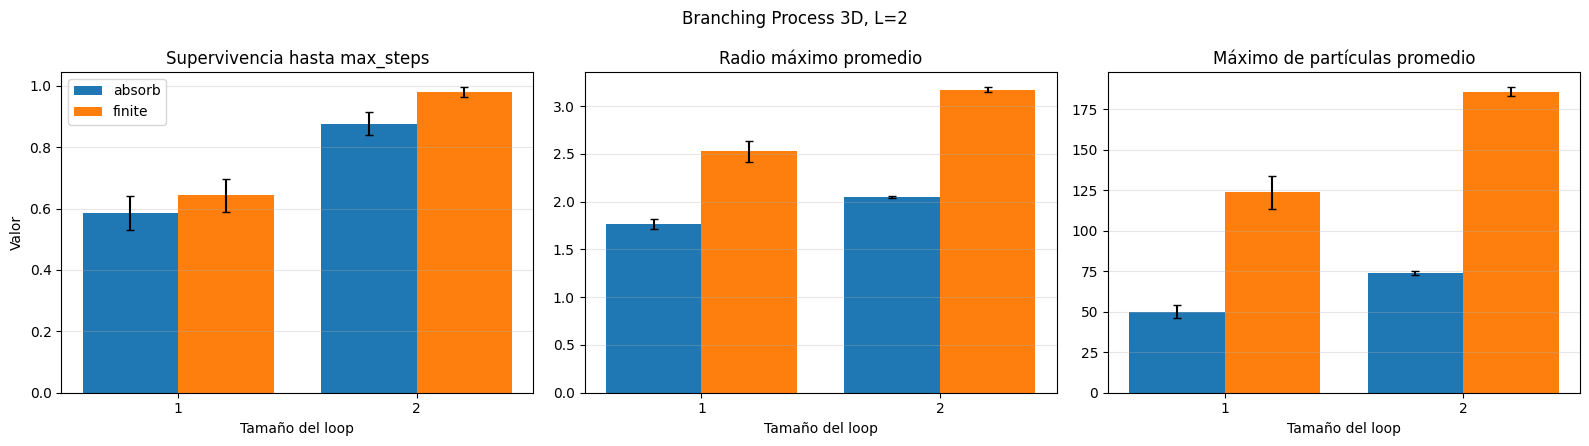

In [ ]:
resumen = (
    df_3d_big_5.groupby(["boundary", "loop_size"])
    .agg(
        n=("censored", "size"),
        sobrevive=("censored", "mean"),
        T_mediana=("T", "median"),
        radio_max=("max_radius", "mean"),
        part_max=("max_particles", "mean"),
        mult_max=("max_mult", "max"),
    )
    .round(3)
)
display(resumen)

g = df_3d_big_5.groupby(["boundary", "loop_size"])
n = g.size()
surv = g["censored"].mean()
se_surv = np.sqrt(surv * (1 - surv) / n)

metricas = [
    ("Supervivencia hasta max_steps", surv, 1.96 * se_surv),
    ("Radio máximo promedio", g["max_radius"].mean(), 1.96 * g["max_radius"].std() / np.sqrt(n)),
    ("Máximo de partículas promedio", g["max_particles"].mean(), 1.96 * g["max_particles"].std() / np.sqrt(n)),
]

bordes = sorted(df_3d_big_5["boundary"].unique())
loops = sorted(df_3d_big_5["loop_size"].unique())
ancho = 0.8 / len(bordes)
x = np.arange(len(loops))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (titulo, valores, err) in zip(axes, metricas):
    for j, b in enumerate(bordes):
        y = [valores[(b, l)] for l in loops]
        e = [err[(b, l)] for l in loops]
        ax.bar(x + j * ancho, y, ancho, yerr=e, capsize=3, label=b)
    ax.set_xticks(x + ancho * (len(bordes) - 1) / 2)
    ax.set_xticklabels(loops)
    ax.set_xlabel("Tamaño del loop")
    ax.set_title(titulo)
    ax.grid(alpha=0.3, axis="y")
axes[0].set_ylabel("Valor")
axes[0].legend()
fig.suptitle("Branching Process 3D, L=2")
plt.tight_layout()
plt.savefig("resumen_3D_L3.png", dpi=300)
plt.show()
